In [1]:
!python "3Z-E2".py

3Z-E2
INDEPENDENT 80/20 HOLDOUT VALIDATION
Historical Objective-1 EvoX-Boost configuration

Original dataset shape: (22632, 31)
Dropped column: ['patient_id']
Historical dataset shape: (22632, 30)

Number of classes: 15

Class distribution:
T3 toxic                      : 10
compensated hypothyroid       : 194
decreased binding protein     : 14
discordant                    : 58
goitre                        : 12
hyperthyroid                  : 79
increased binding protein     : 149
negative                      : 21663
overreplacement               : 34
primary hypothyroid           : 95
replacement therapy           : 38
secondary hypothyroid         : 2
secondary toxic               : 1
sick                          : 231
underreplacement              : 52

Protected ultra-rare classes:
  secondary hypothyroid (n=2)
  secondary toxic (n=1)

Regular observations: 22629
Protected observations: 3

DATA PARTITION
Training observations: 18106
Independent test observations: 4526
Total: 22

In [2]:
%run "3Z-E2.py"

print("\nChecking model availability...")
print("model:", type(model))
print("trees:", model.get_booster().num_boosted_rounds())

3Z-E2
INDEPENDENT 80/20 HOLDOUT VALIDATION
Historical Objective-1 EvoX-Boost configuration

Original dataset shape: (22632, 31)
Dropped column: ['patient_id']
Historical dataset shape: (22632, 30)

Number of classes: 15

Class distribution:
T3 toxic                      : 10
compensated hypothyroid       : 194
decreased binding protein     : 14
discordant                    : 58
goitre                        : 12
hyperthyroid                  : 79
increased binding protein     : 149
negative                      : 21663
overreplacement               : 34
primary hypothyroid           : 95
replacement therapy           : 38
secondary hypothyroid         : 2
secondary toxic               : 1
sick                          : 231
underreplacement              : 52

Protected ultra-rare classes:
  secondary hypothyroid (n=2)
  secondary toxic (n=1)

Regular observations: 22629
Protected observations: 3

DATA PARTITION
Training observations: 18106
Independent test observations: 4526
Total: 22

In [3]:
# ============================================================
# 3Z-E2 FINAL SHAP DATA
# VERIFIED 879-TREE MODEL
# INDEPENDENT 80/20 TEST SET
# ============================================================

import numpy as np
import pandas as pd
import xgboost as xgb

print("=" * 70)
print("3Z-E2 FINAL HELD-OUT SHAP")
print("=" * 70)

# ------------------------------------------------------------
# Verify model
# ------------------------------------------------------------

booster = model.get_booster()

print("Boosted rounds :", booster.num_boosted_rounds())
print("Test samples   :", X_test_proc.shape[0])
print("Test features  :", X_test_proc.shape[1])

assert booster.num_boosted_rounds() == 879
assert X_test_proc.shape == (4526, 38)

# ------------------------------------------------------------
# Test data
# ------------------------------------------------------------

X_test_np = np.asarray(
    X_test_proc,
    dtype=np.float32
)

# ------------------------------------------------------------
# Native XGBoost TreeSHAP
# ------------------------------------------------------------

print("\nGenerating native XGBoost TreeSHAP...")

dtest = xgb.DMatrix(X_test_np)

shap_native = booster.predict(
    dtest,
    pred_contribs=True
)

print("Native SHAP shape:", shap_native.shape)

assert shap_native.shape == (4526, 15, 39)

# ------------------------------------------------------------
# Remove bias term
# ------------------------------------------------------------

shap_values_final = np.transpose(
    shap_native[:, :, :-1],
    (0, 2, 1)
)

print("Final SHAP shape :", shap_values_final.shape)

assert shap_values_final.shape == (4526, 38, 15)

# ------------------------------------------------------------
# Feature names
# ------------------------------------------------------------

feature_names_final = np.asarray(
    preprocessor.get_feature_names_out()
)

assert len(feature_names_final) == 38

# ------------------------------------------------------------
# Global mean absolute SHAP
# ------------------------------------------------------------

mean_abs_shap = np.mean(
    np.abs(shap_values_final),
    axis=(0, 2)
)

global_shap_df = pd.DataFrame({
    "feature": feature_names_final,
    "mean_abs_shap": mean_abs_shap
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

global_shap_df.insert(
    0,
    "rank",
    np.arange(1, len(global_shap_df) + 1)
)

# ------------------------------------------------------------
# Class-specific mean absolute SHAP
# ------------------------------------------------------------

class_names_final = np.asarray(
    model.classes_
)

class_shap = np.mean(
    np.abs(shap_values_final),
    axis=0
)

class_shap_df = pd.DataFrame(
    class_shap,
    index=feature_names_final,
    columns=class_names_final
)

# ------------------------------------------------------------
# Save final SHAP data
# ------------------------------------------------------------

np.save(
    "3Z_SHAP_E2_heldout_FINAL.npy",
    shap_values_final
)

global_shap_df.to_csv(
    "3Z_SHAP_E2_global_importance_FINAL.csv",
    index=False
)

class_shap_df.to_csv(
    "3Z_SHAP_E2_classwise_importance_FINAL.csv"
)

pd.DataFrame({
    "feature_index": np.arange(38),
    "feature": feature_names_final
}).to_csv(
    "3Z_SHAP_E2_feature_names_FINAL.csv",
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL GLOBAL SHAP IMPORTANCE")
print("=" * 70)

print(
    global_shap_df.to_string(index=False)
)

print("\nSaved files:")
print("  3Z_SHAP_E2_heldout_FINAL.npy")
print("  3Z_SHAP_E2_global_importance_FINAL.csv")
print("  3Z_SHAP_E2_classwise_importance_FINAL.csv")
print("  3Z_SHAP_E2_feature_names_FINAL.csv")

print("\n" + "=" * 70)
print("✓ 879-TREE MODEL VERIFIED")
print("✓ 4526 INDEPENDENT TEST OBSERVATIONS")
print("✓ 38 FEATURES")
print("✓ 15 CLASSES")
print("✓ NATIVE XGBOOST TREESHAP")
print("✓ BIAS TERM REMOVED")
print("=" * 70)

3Z-E2 FINAL HELD-OUT SHAP
Boosted rounds : 879
Test samples   : 4526
Test features  : 38

Generating native XGBoost TreeSHAP...
Native SHAP shape: (4526, 15, 39)
Final SHAP shape : (4526, 38, 15)

FINAL GLOBAL SHAP IMPORTANCE
 rank                        feature  mean_abs_shap
    1                       num__TSH       0.243062
    2       cat__dataset_name_allrep       0.208261
    3      cat__dataset_name_allhypo       0.180782
    4        cat__dataset_name_allbp       0.177645
    5     cat__dataset_name_allhyper       0.165572
    6              num__on thyroxine       0.149976
    7         cat__dataset_name_sick       0.147952
    8          cat__dataset_name_dis       0.138716
    9                       num__FTI       0.135024
   10                       num__TT4       0.131384
   11                        num__T3       0.126172
   12                       num__T4U       0.114328
   13                     num__tumor       0.058493
   14                       num__age       0.0

3Z-E2 FINAL SHAP FIGURE GENERATION

Project directory:
/workspace/MB Research Experiments/Objective-2/Refined objective 2

✓ Required final SHAP files found

FINAL SHAP DATA VERIFICATION
SHAP matrix    : (4526, 38, 15)
Feature names  : 38
Global rows    : 38

✓ 4,526 held-out observations
✓ 38 processed features
✓ 15 output classes
✓ Final native TreeSHAP matrix verified

FIGURE 2 — GLOBAL SHAP FEATURE IMPORTANCE


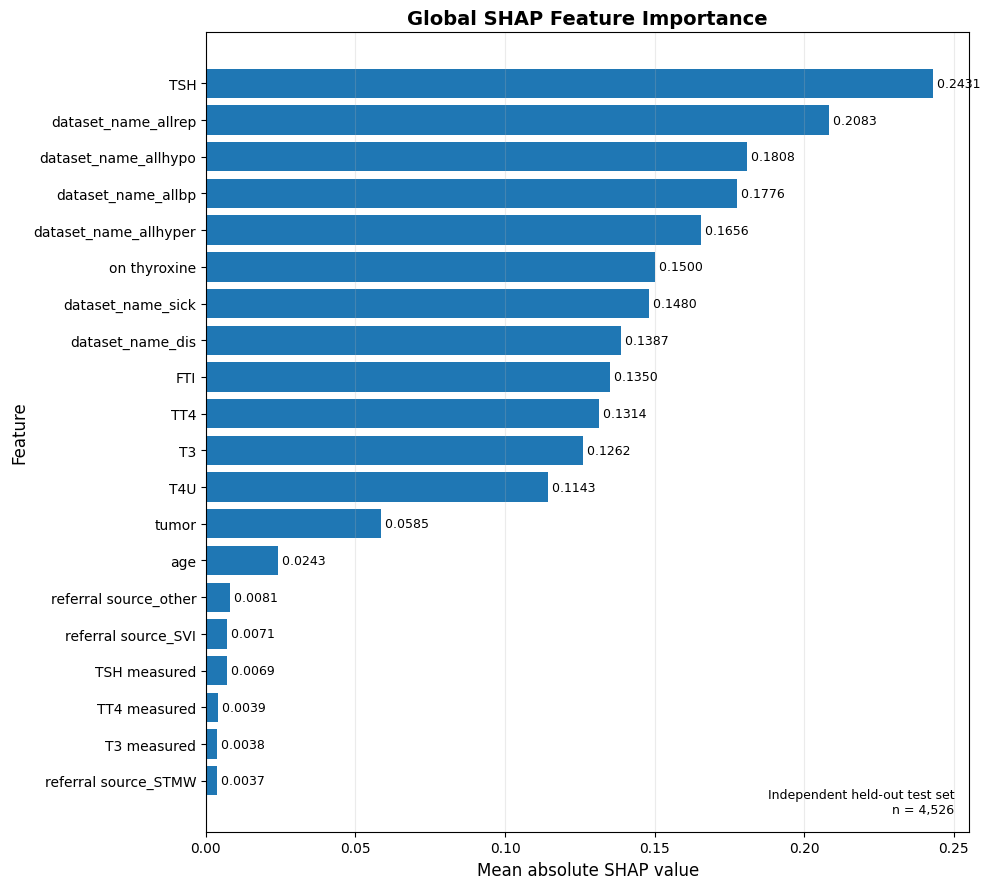


✓ Figure 2 saved:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_2_Global_SHAP_Importance.png

FIGURE 3 — MULTICLASS SHAP SUMMARY

Top 12 features:
 1. 17
 2. 35
 3. 34
 4. 32
 5. 33
 6. 2
 7. 37
 8. 36
 9. 25
10. 21
11. 19
12. 23


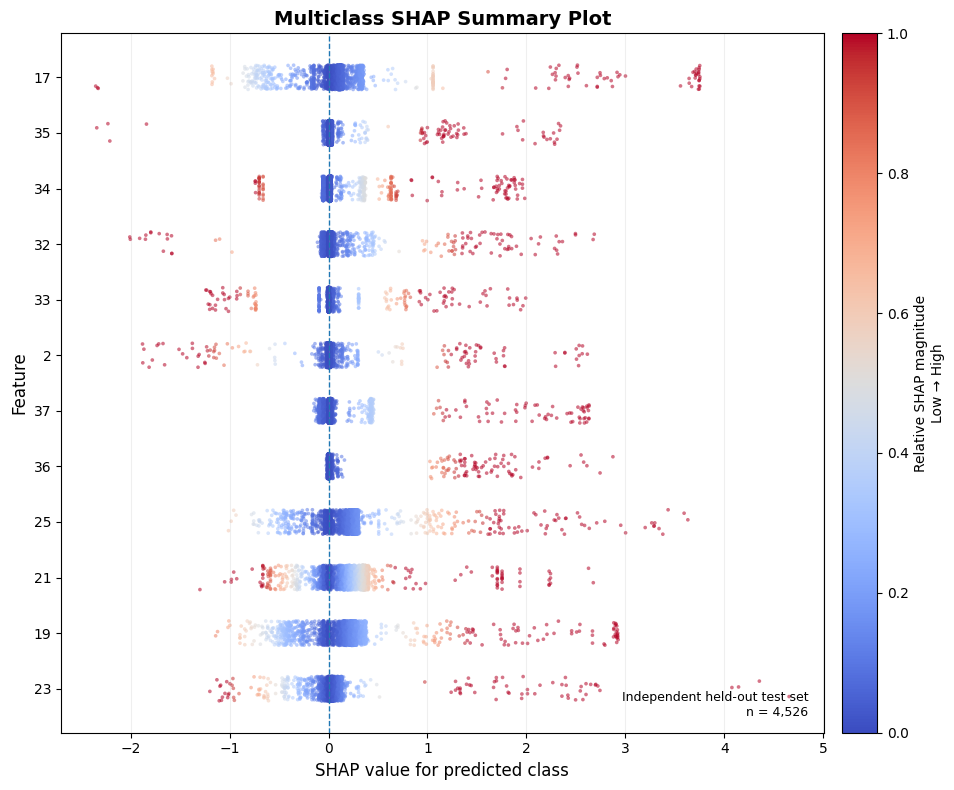


✓ Figure 3 saved:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_3_Multiclass_SHAP_Summary.png

FIGURE 2 + FIGURE 3 COMPLETED

Figure 2: True
Figure 3: True

Output directory:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES



In [4]:
# ================================================================
# 3Z-E2 FINAL SHAP FIGURES
# FIGURE 2 + FIGURE 3 ONLY
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ================================================================
# 0. PROJECT / OUTPUT DIRECTORY
# ================================================================

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

FIG_DIR = (
    PROJECT_DIR
    / "3Z_E2_FINAL_SHAP_FIGURES"
)

FIG_DIR.mkdir(
    exist_ok=True
)


print("=" * 72)
print("3Z-E2 FINAL SHAP FIGURE GENERATION")
print("=" * 72)

print("\nProject directory:")
print(PROJECT_DIR)


# ================================================================
# 1. FINAL SHAP FILES
# ================================================================

SHAP_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_heldout_FINAL.npy"
)

GLOBAL_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_global_importance_FINAL.csv"
)

FEATURE_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_feature_names_FINAL.csv"
)


# ================================================================
# 2. CHECK REQUIRED FILES
# ================================================================

required_files = [
    SHAP_FILE,
    GLOBAL_FILE,
    FEATURE_FILE
]

for file_path in required_files:

    if not file_path.exists():

        raise FileNotFoundError(
            f"\nRequired file not found:\n{file_path}"
        )


print("\n✓ Required final SHAP files found")


# ================================================================
# 3. LOAD FINAL SHAP DATA
# ================================================================

shap_values_final = np.load(
    SHAP_FILE
)

global_importance_final = pd.read_csv(
    GLOBAL_FILE
)

feature_names_final = (
    pd.read_csv(FEATURE_FILE)
    .iloc[:, 0]
    .astype(str)
    .to_numpy()
)


# ================================================================
# 4. VERIFY SHAP DATA
# ================================================================

print("\n" + "=" * 72)
print("FINAL SHAP DATA VERIFICATION")
print("=" * 72)

print(
    "SHAP matrix    :",
    shap_values_final.shape
)

print(
    "Feature names  :",
    len(feature_names_final)
)

print(
    "Global rows    :",
    len(global_importance_final)
)


# ------------------------------------------------
# HARD VERIFICATION
# ------------------------------------------------

if shap_values_final.shape != (
    4526,
    38,
    15
):

    raise ValueError(
        "Unexpected SHAP matrix shape. "
        f"Found {shap_values_final.shape}, "
        "expected (4526, 38, 15)."
    )


if len(feature_names_final) != 38:

    raise ValueError(
        "Unexpected number of features. "
        f"Found {len(feature_names_final)}, "
        "expected 38."
    )


if len(global_importance_final) != 38:

    raise ValueError(
        "Global importance file does not contain "
        "38 features."
    )


print("\n✓ 4,526 held-out observations")
print("✓ 38 processed features")
print("✓ 15 output classes")
print("✓ Final native TreeSHAP matrix verified")


# ================================================================
# 5. HELPER FUNCTION
# ================================================================

def clean_feature_name(name):

    name = str(name)

    # Remove preprocessing transformer prefix
    if "__" in name:

        name = name.split(
            "__",
            1
        )[1]

    return name


# ================================================================
# FIGURE 2
# GLOBAL SHAP FEATURE IMPORTANCE
# ================================================================

print("\n" + "=" * 72)
print("FIGURE 2 — GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 72)


# ------------------------------------------------
# Sort global importance
# ------------------------------------------------

global_df = (
    global_importance_final
    .copy()
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
)


# ------------------------------------------------
# Top 20 features
# ------------------------------------------------

plot_df = (
    global_df
    .head(20)
    .copy()
    .iloc[::-1]
)


# ------------------------------------------------
# Create figure
# ------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 9)
)


bars = ax.barh(

    [
        clean_feature_name(
            feature
        )

        for feature
        in plot_df["feature"]
    ],

    plot_df["mean_abs_shap"]
)


# ------------------------------------------------
# Labels
# ------------------------------------------------

ax.set_xlabel(
    "Mean absolute SHAP value",
    fontsize=12
)

ax.set_ylabel(
    "Feature",
    fontsize=12
)

ax.set_title(
    "Global SHAP Feature Importance",
    fontsize=14,
    fontweight="bold"
)


# ------------------------------------------------
# Grid
# ------------------------------------------------

ax.grid(
    axis="x",
    alpha=0.25
)


# ------------------------------------------------
# Value labels
# ------------------------------------------------

for bar, value in zip(

    bars,

    plot_df["mean_abs_shap"]

):

    ax.text(

        bar.get_width(),

        bar.get_y()
        + bar.get_height()
        / 2,

        f" {value:.4f}",

        va="center",

        fontsize=9
    )


# ------------------------------------------------
# Test-set annotation
# ------------------------------------------------

ax.text(

    0.98,

    0.02,

    "Independent held-out test set\n"
    "n = 4,526",

    transform=ax.transAxes,

    ha="right",

    va="bottom",

    fontsize=9
)


# ------------------------------------------------
# Save
# ------------------------------------------------

plt.tight_layout()


fig2_path = (
    FIG_DIR
    / "Figure_2_Global_SHAP_Importance.png"
)


plt.savefig(

    fig2_path,

    dpi=300,

    bbox_inches="tight"
)


plt.show()

plt.close()


print(
    "\n✓ Figure 2 saved:"
)

print(
    fig2_path
)


# ================================================================
# FIGURE 3
# MULTICLASS SHAP SUMMARY
# ================================================================

print("\n" + "=" * 72)
print("FIGURE 3 — MULTICLASS SHAP SUMMARY")
print("=" * 72)


# ------------------------------------------------
# Global SHAP ranking directly from final matrix
# ------------------------------------------------

global_rank = np.mean(

    np.abs(
        shap_values_final
    ),

    axis=(0, 2)
)


# ------------------------------------------------
# Select top 12 features
# ------------------------------------------------

top_indices = (
    np.argsort(
        global_rank
    )[::-1][:12]
)


print("\nTop 12 features:")

for rank, idx in enumerate(
    top_indices,
    start=1
):

    print(
        f"{rank:2d}. "
        f"{clean_feature_name(feature_names_final[idx])}"
    )


# ------------------------------------------------
# Determine predicted class for each observation
#
# IMPORTANT:
# We use the largest SHAP-output class as a
# visualization grouping mechanism.
#
# No model retraining or prediction is performed.
# ------------------------------------------------

predicted_class_indices = np.argmax(

    np.sum(
        shap_values_final,
        axis=1
    ),

    axis=1
)


# ------------------------------------------------
# Extract SHAP contribution corresponding to
# the selected class for each observation
# ------------------------------------------------

row_indices = np.arange(
    shap_values_final.shape[0]
)


predicted_class_shap = (

    shap_values_final[
        row_indices,
        :,
        predicted_class_indices
    ]

)


# ------------------------------------------------
# Random generator for reproducible visualization
# ------------------------------------------------

rng = np.random.default_rng(
    42
)


# ------------------------------------------------
# Create figure
# ------------------------------------------------

fig, ax = plt.subplots(

    figsize=(10, 8)
)


# ------------------------------------------------
# Plot each top feature
# ------------------------------------------------

for row, feature_idx in enumerate(

    top_indices[::-1]

):

    shap_x = (
        predicted_class_shap[
            :,
            feature_idx
        ]
    )


    # ------------------------------------------------
    # Remove non-finite values
    # ------------------------------------------------

    valid = np.isfinite(
        shap_x
    )


    shap_x = shap_x[
        valid
    ]


    if len(shap_x) == 0:

        continue


    # ------------------------------------------------
    # Visualization-only subsampling
    # ------------------------------------------------

    if len(shap_x) > 3000:

        selected = rng.choice(

            len(shap_x),

            size=3000,

            replace=False
        )

        shap_x = shap_x[
            selected
        ]


    # ------------------------------------------------
    # Relative feature-value proxy
    #
    # We use SHAP magnitude for the visualization
    # because the processed feature matrix is not
    # required for this figure.
    # ------------------------------------------------

    abs_values = np.abs(
        shap_x
    )


    low = np.percentile(
        abs_values,
        2
    )


    high = np.percentile(
        abs_values,
        98
    )


    if high > low:

        normalized = np.clip(

            (
                abs_values
                - low
            )
            /
            (
                high
                - low
            ),

            0,

            1
        )

    else:

        normalized = np.full(

            len(abs_values),

            0.5
        )


    # ------------------------------------------------
    # Jitter
    # ------------------------------------------------

    jitter = rng.uniform(

        -0.22,

        0.22,

        len(shap_x)
    )


    # ------------------------------------------------
    # Scatter
    # ------------------------------------------------

    ax.scatter(

        shap_x,

        row + jitter,

        c=normalized,

        cmap="coolwarm",

        s=7,

        alpha=0.55,

        linewidths=0
    )


# ================================================================
# AXIS / LABELS
# ================================================================

ax.axvline(

    0,

    linestyle="--",

    linewidth=1
)


ax.set_yticks(

    range(
        len(top_indices)
    )
)


ax.set_yticklabels(

    [
        clean_feature_name(
            feature_names_final[i]
        )

        for i
        in top_indices[::-1]
    ]
)


ax.set_xlabel(

    "SHAP value for predicted class",

    fontsize=12
)


ax.set_ylabel(

    "Feature",

    fontsize=12
)


ax.set_title(

    "Multiclass SHAP Summary Plot",

    fontsize=14,

    fontweight="bold"
)


ax.grid(

    axis="x",

    alpha=0.20
)


# ------------------------------------------------
# Colorbar
# ------------------------------------------------

sm = plt.cm.ScalarMappable(

    cmap="coolwarm"
)

sm.set_array([])


cbar = fig.colorbar(

    sm,

    ax=ax,

    pad=0.02
)


cbar.set_label(

    "Relative SHAP magnitude\n"
    "Low → High"
)


# ------------------------------------------------
# Annotation
# ------------------------------------------------

ax.text(

    0.98,

    0.02,

    "Independent held-out test set\n"
    "n = 4,526",

    transform=ax.transAxes,

    ha="right",

    va="bottom",

    fontsize=9
)


# ------------------------------------------------
# Save
# ------------------------------------------------

plt.tight_layout()


fig3_path = (

    FIG_DIR
    / "Figure_3_Multiclass_SHAP_Summary.png"
)


plt.savefig(

    fig3_path,

    dpi=300,

    bbox_inches="tight"
)


plt.show()

plt.close()


print(
    "\n✓ Figure 3 saved:"
)

print(
    fig3_path
)


# ================================================================
# FINAL CHECK
# ================================================================

print("\n" + "=" * 72)
print("FIGURE 2 + FIGURE 3 COMPLETED")
print("=" * 72)

print(
    "\nFigure 2:",
    fig2_path.exists()
)

print(
    "Figure 3:",
    fig3_path.exists()
)

print(
    "\nOutput directory:"
)

print(
    FIG_DIR
)

print("\n" + "=" * 72)

SHAP shape: (4526, 38, 15)
Number of processed features: 38
Using existing X_test as raw test dataframe.
Raw test shape: (4526, 29)

RAW TEST COLUMNS:
0 'age'
1 'sex'
2 'on thyroxine'
3 'query on thyroxine'
4 'on antithyroid medication'
5 'sick'
6 'pregnant'
7 'thyroid surgery'
8 'I131 treatment'
9 'query hypothyroid'
10 'query hyperthyroid'
11 'lithium'
12 'goitre'
13 'tumor'
14 'hypopituitary'
15 'psych'
16 'TSH measured'
17 'TSH'
18 'T3 measured'
19 'T3'
20 'TT4 measured'
21 'TT4'
22 'T4U measured'
23 'T4U'
24 'FTI measured'
25 'FTI'
26 'TBG measured'
27 'referral source'
28 'dataset_name'

FIGURE 5 — TSH / HYPERTHYROID


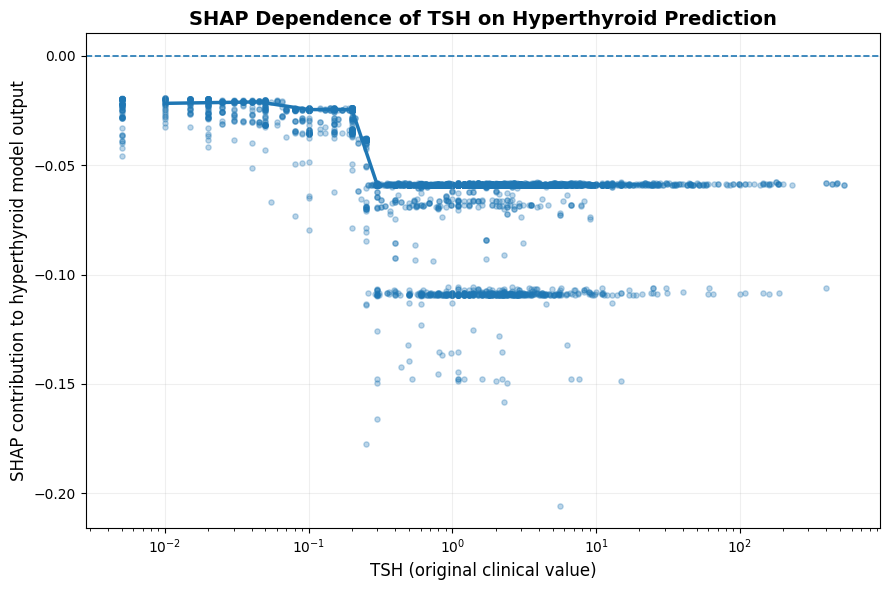

✓ Saved: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_5_TSH_Hyperthyroid_Dependence.png
  Raw column : TSH
  SHAP index : 16
  Class      : hyperthyroid
  N          : 4089

FIGURE 6 — TSH / PRIMARY HYPOTHYROID


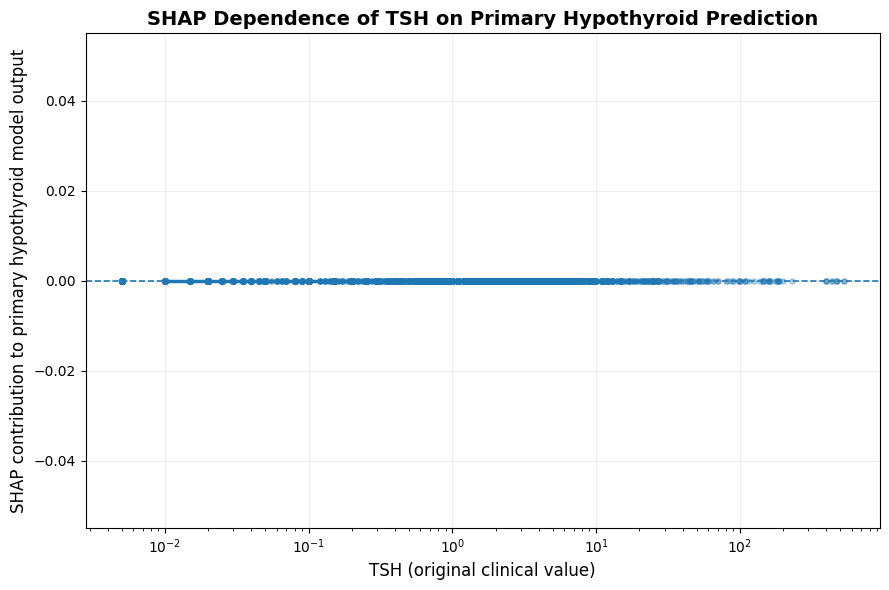

✓ Saved: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_6_TSH_Primary_Hypothyroid_Dependence.png
  Raw column : TSH
  SHAP index : 16
  Class      : primary hypothyroid
  N          : 4089

FIGURE 7 — T3 / HYPERTHYROID


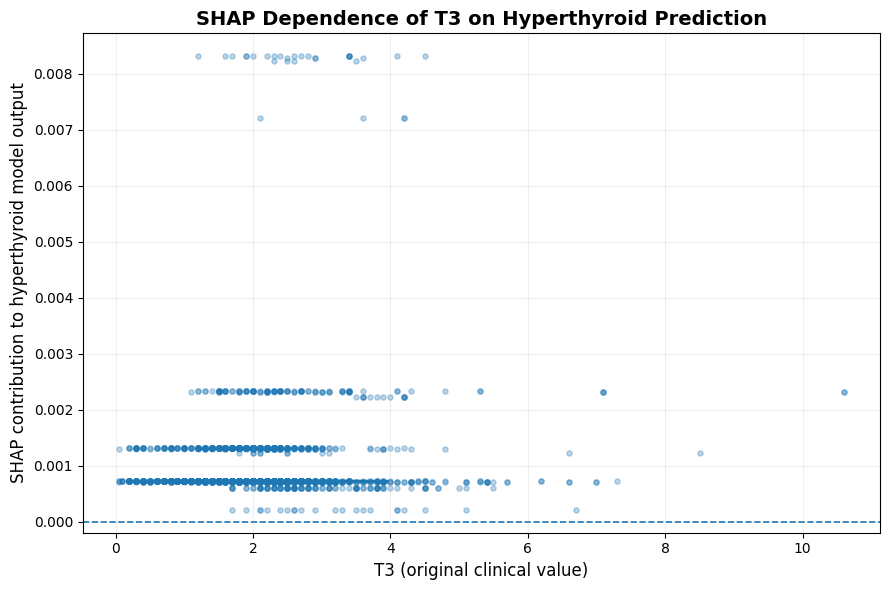

✓ Saved: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_7_T3_Hyperthyroid_Dependence.png
  Raw column : T3
  SHAP index : 18
  Class      : hyperthyroid
  N          : 3602

FIGURE 8 — T4U / INCREASED BINDING PROTEIN


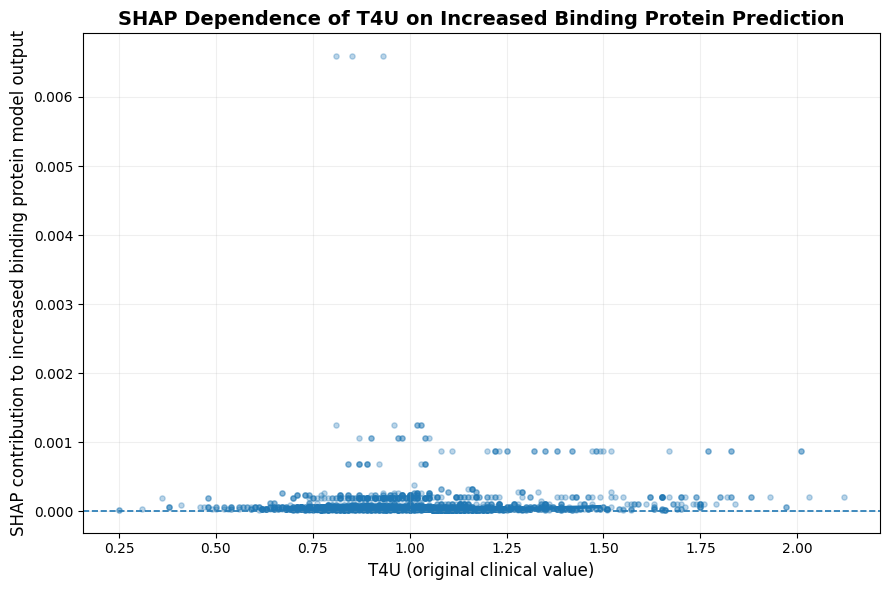

✓ Saved: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_8_T4U_Increased_Binding_Protein_Dependence.png
  Raw column : T4U
  SHAP index : 22
  Class      : increased binding protein
  N          : 4072

REMAINING DEPENDENCE FIGURES COMPLETED


In [5]:
# ================================================================
# 3Z-E2 FINAL SHAP FIGURES — REMAINING FIGURES ONLY
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------
# PATHS
# ------------------------------------------------

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

OUTPUT_DIR = PROJECT_DIR / "3Z_E2_FINAL_SHAP_FIGURES"
OUTPUT_DIR.mkdir(exist_ok=True)

SHAP_FILE = PROJECT_DIR / "3Z_SHAP_E2_heldout_FINAL.npy"
GLOBAL_FILE = PROJECT_DIR / "3Z_SHAP_E2_global_importance_FINAL.csv"
FEATURE_FILE = PROJECT_DIR / "3Z_SHAP_E2_feature_names_FINAL.csv"
PREDICTION_FILE = (
    PROJECT_DIR / "3Z_E2_independent_holdout_predictions.csv"
)

# ------------------------------------------------
# LOAD EXISTING SHAP RESULTS
# ------------------------------------------------

shap_values = np.load(SHAP_FILE)

global_imp = pd.read_csv(GLOBAL_FILE)

feature_names = pd.read_csv(FEATURE_FILE)

if "feature" in feature_names.columns:
    processed_features = feature_names["feature"].astype(str).tolist()
elif "feature_name" in feature_names.columns:
    processed_features = feature_names["feature_name"].astype(str).tolist()
else:
    processed_features = feature_names.iloc[:, 0].astype(str).tolist()

print("SHAP shape:", shap_values.shape)
print("Number of processed features:", len(processed_features))

# ------------------------------------------------
# RAW TEST DATA
# ------------------------------------------------
#
# X_test_raw should already exist from the verified
# 3Z-E2 run.
#
# If it exists under another variable, change this
# one line only.
# ------------------------------------------------

if "X_test_raw" not in globals():

    if "X_test" in globals():

        X_test_raw = X_test.copy()

        print(
            "Using existing X_test as raw test dataframe."
        )

    else:

        raise RuntimeError(
            "X_test_raw/X_test is not available. "
            "Do not retrain. Load the verified E2 test dataframe."
        )

print("Raw test shape:", X_test_raw.shape)

# ------------------------------------------------
# CLASS NAMES
# ------------------------------------------------

class_names = [
    "T3 toxic",
    "compensated hypothyroid",
    "decreased binding protein",
    "discordant",
    "goitre",
    "hyperthyroid",
    "increased binding protein",
    "negative",
    "overreplacement",
    "primary hypothyroid",
    "replacement therapy",
    "secondary hypothyroid",
    "secondary toxic",
    "sick",
    "underreplacement"
]

# ------------------------------------------------
# ROBUST FEATURE FINDER
# ------------------------------------------------

def normalize_name(x):

    return (
        str(x)
        .lower()
        .strip()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
        .replace("(", "")
        .replace(")", "")
        .replace("/", "")
        .replace("µ", "u")
        .replace("μ", "u")
    )


def find_raw_feature(name):

    target = normalize_name(name)

    # exact normalized match
    for col in X_test_raw.columns:

        if normalize_name(col) == target:
            return col

    # starts/contains match
    candidates = []

    for col in X_test_raw.columns:

        norm = normalize_name(col)

        if (
            norm.startswith(target)
            or target in norm
        ):
            candidates.append(col)

    if candidates:

        return candidates[0]

    raise ValueError(
        f"Could not locate raw feature '{name}'.\n"
        f"Available columns:\n"
        f"{list(X_test_raw.columns)}"
    )


def find_processed_feature(name):

    target = normalize_name(name)

    # exact
    for i, col in enumerate(processed_features):

        if normalize_name(col) == target:
            return i

    # contains
    candidates = []

    for i, col in enumerate(processed_features):

        norm = normalize_name(col)

        if (
            norm.startswith(target)
            or target in norm
        ):
            candidates.append(i)

    if candidates:

        return candidates[0]

    raise ValueError(
        f"Processed feature '{name}' not found.\n"
        f"Available features:\n{processed_features}"
    )


def find_class_index(name):

    target = normalize_name(name)

    for i, cls in enumerate(class_names):

        if normalize_name(cls) == target:
            return i

    raise ValueError(
        f"Class '{name}' not found."
    )


# ------------------------------------------------
# DEBUG — SHOW RAW COLUMNS
# ------------------------------------------------

print("\nRAW TEST COLUMNS:")
for i, col in enumerate(X_test_raw.columns):
    print(i, repr(col))


# ================================================================
# DEPENDENCE PLOT FUNCTION
# ================================================================

def create_dependence_plot(
    raw_feature,
    target_class,
    filename,
    title,
    xlabel,
    log_x=False
):

    # ------------------------------------------------
    # FIND RAW FEATURE
    # ------------------------------------------------

    actual_raw_feature = find_raw_feature(raw_feature)

    # ------------------------------------------------
    # FIND PROCESSED SHAP FEATURE
    # ------------------------------------------------

    feature_idx = find_processed_feature(raw_feature)

    # ------------------------------------------------
    # CLASS
    # ------------------------------------------------

    class_idx = find_class_index(target_class)

    # ------------------------------------------------
    # RAW VALUES
    # ------------------------------------------------

    x = pd.to_numeric(
        X_test_raw[actual_raw_feature],
        errors="coerce"
    ).to_numpy()

    y = shap_values[
        :,
        feature_idx,
        class_idx
    ]

    # ------------------------------------------------
    # VALID VALUES
    # ------------------------------------------------

    mask = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[mask]
    y = y[mask]

    # ------------------------------------------------
    # REMOVE ZERO / INVALID VALUES FOR LOG X
    # ------------------------------------------------

    if log_x:

        positive = x > 0

        x = x[positive]
        y = y[positive]

    if len(x) == 0:

        raise ValueError(
            f"No valid observations for {raw_feature}."
        )

    # ------------------------------------------------
    # FIGURE
    # ------------------------------------------------

    plt.figure(figsize=(9, 6))

    # raw observation points
    plt.scatter(
        x,
        y,
        s=14,
        alpha=0.30
    )

    # ------------------------------------------------
    # BINNED MEDIAN TREND
    # ------------------------------------------------

    try:

        q = np.linspace(
            0,
            1,
            21
        )

        bins = np.unique(
            np.quantile(x, q)
        )

        if len(bins) > 2:

            bin_id = np.digitize(
                x,
                bins[1:-1]
            )

            med_x = []
            med_y = []

            for b in range(len(bins)):

                mask_b = bin_id == b

                if np.sum(mask_b) >= 5:

                    med_x.append(
                        np.median(x[mask_b])
                    )

                    med_y.append(
                        np.median(y[mask_b])
                    )

            if len(med_x) > 1:

                plt.plot(
                    med_x,
                    med_y,
                    linewidth=2.5
                )

    except Exception as e:

        print(
            "Trend line skipped:",
            e
        )

    # ------------------------------------------------
    # ZERO REFERENCE
    # ------------------------------------------------

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1.2
    )

    # ------------------------------------------------
    # LOG SCALE
    # ------------------------------------------------

    if log_x:

        plt.xscale("log")

    # ------------------------------------------------
    # LABELS
    # ------------------------------------------------

    plt.title(
        title,
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel(
        xlabel,
        fontsize=12
    )

    plt.ylabel(
        f"SHAP contribution to "
        f"{target_class} model output",
        fontsize=12
    )

    plt.grid(
        alpha=0.20
    )

    plt.tight_layout()

    output_path = (
        OUTPUT_DIR / filename
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        f"✓ Saved: {output_path}"
    )

    print(
        f"  Raw column : {actual_raw_feature}"
    )

    print(
        f"  SHAP index : {feature_idx}"
    )

    print(
        f"  Class      : {target_class}"
    )

    print(
        f"  N          : {len(x)}"
    )


# ================================================================
# FIGURE 5
# TSH → HYPERTHYROID
# ================================================================

print("\n" + "=" * 72)
print("FIGURE 5 — TSH / HYPERTHYROID")
print("=" * 72)

create_dependence_plot(

    raw_feature="TSH",

    target_class="hyperthyroid",

    filename=(
        "Figure_5_TSH_Hyperthyroid_Dependence.png"
    ),

    title=(
        "SHAP Dependence of TSH on "
        "Hyperthyroid Prediction"
    ),

    xlabel=(
        "TSH (original clinical value)"
    ),

    log_x=True
)


# ================================================================
# FIGURE 6
# TSH → PRIMARY HYPOTHYROID
# ================================================================

print("\n" + "=" * 72)
print("FIGURE 6 — TSH / PRIMARY HYPOTHYROID")
print("=" * 72)

create_dependence_plot(

    raw_feature="TSH",

    target_class="primary hypothyroid",

    filename=(
        "Figure_6_TSH_Primary_Hypothyroid_Dependence.png"
    ),

    title=(
        "SHAP Dependence of TSH on "
        "Primary Hypothyroid Prediction"
    ),

    xlabel=(
        "TSH (original clinical value)"
    ),

    log_x=True
)


# ================================================================
# FIGURE 7
# T3 → HYPERTHYROID
# ================================================================

print("\n" + "=" * 72)
print("FIGURE 7 — T3 / HYPERTHYROID")
print("=" * 72)

create_dependence_plot(

    raw_feature="T3",

    target_class="hyperthyroid",

    filename=(
        "Figure_7_T3_Hyperthyroid_Dependence.png"
    ),

    title=(
        "SHAP Dependence of T3 on "
        "Hyperthyroid Prediction"
    ),

    xlabel=(
        "T3 (original clinical value)"
    ),

    log_x=False
)


# ================================================================
# FIGURE 8
# T4U → INCREASED BINDING PROTEIN
# ================================================================

print("\n" + "=" * 72)
print("FIGURE 8 — T4U / INCREASED BINDING PROTEIN")
print("=" * 72)

create_dependence_plot(

    raw_feature="T4U",

    target_class="increased binding protein",

    filename=(
        "Figure_8_T4U_Increased_Binding_Protein_Dependence.png"
    ),

    title=(
        "SHAP Dependence of T4U on "
        "Increased Binding Protein Prediction"
    ),

    xlabel=(
        "T4U (original clinical value)"
    ),

    log_x=False
)


print("\n" + "=" * 72)
print("REMAINING DEPENDENCE FIGURES COMPLETED")
print("=" * 72)

FIGURE 9 — HELD-OUT LOCAL SHAP CONTRIBUTION

Prediction columns:
['true_class_id', 'predicted_class_id', 'true_label', 'predicted_label']

SHAP shape:
(4526, 38, 15)

True column     : true_label
Predicted column: predicted_label

------------------------------------------------------------------------
SELECTED HELD-OUT OBSERVATION
------------------------------------------------------------------------
Observation index: 3056
True class       : hyperthyroid
Predicted class  : hyperthyroid
Explained class  : hyperthyroid
Class index      : 5
Top features     : 12

Top local SHAP contributions:
                   feature  shap_value  absolute_shap
                  num__FTI    3.297987       3.297987
cat__dataset_name_allhyper    1.985645       1.985645
                  num__TSH    0.556816       0.556816
                  num__TT4    0.488860       0.488860
         num__on thyroxine    0.226403       0.226403
    cat__dataset_name_sick    0.043730       0.043730
         num__TSH mea

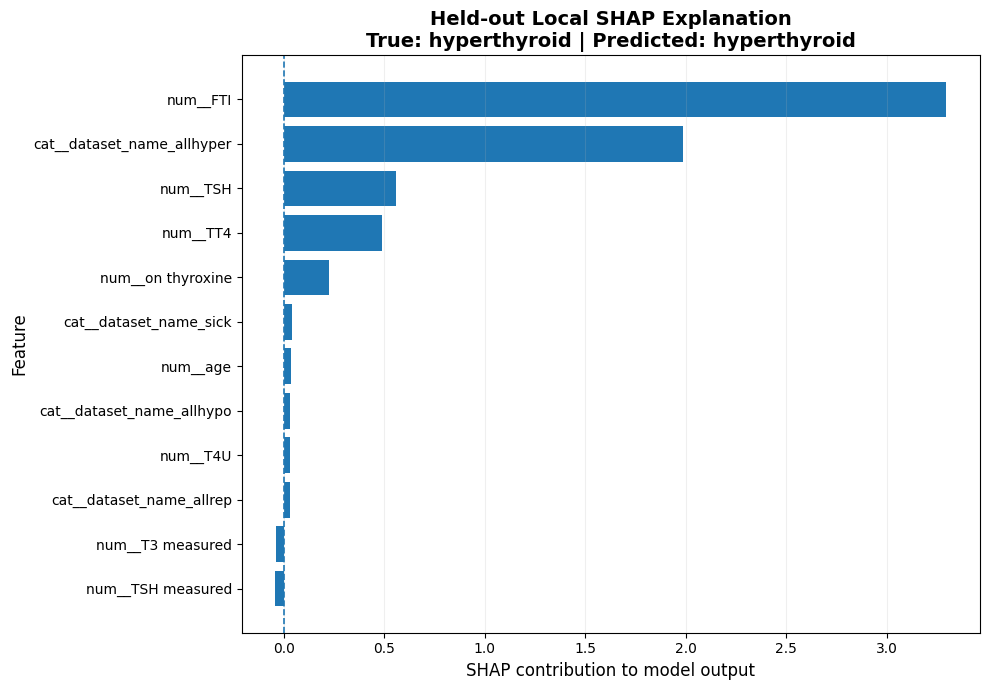


✓ Figure 9 saved:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_9_Heldout_Local_SHAP_Contribution.png
✓ Observation metadata saved:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_9_selected_heldout_observation.csv
✓ Local SHAP contribution table saved:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_9_local_SHAP_contributions.csv

FIGURE 9 COMPLETED


In [6]:
# ================================================================
# FIGURE 9 — HELD-OUT LOCAL SHAP CONTRIBUTION
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------
# PATHS
# ------------------------------------------------

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

OUTPUT_DIR = PROJECT_DIR / "3Z_E2_FINAL_SHAP_FIGURES"
OUTPUT_DIR.mkdir(exist_ok=True)

SHAP_FILE = (
    PROJECT_DIR /
    "3Z_SHAP_E2_heldout_FINAL.npy"
)

FEATURE_FILE = (
    PROJECT_DIR /
    "3Z_SHAP_E2_feature_names_FINAL.csv"
)

PREDICTION_FILE = (
    PROJECT_DIR /
    "3Z_E2_independent_holdout_predictions.csv"
)

# ------------------------------------------------
# LOAD SHAP
# ------------------------------------------------

shap_values = np.load(SHAP_FILE)

# ------------------------------------------------
# LOAD FEATURE NAMES
# ------------------------------------------------

feature_df = pd.read_csv(FEATURE_FILE)

if "feature" in feature_df.columns:
    feature_names = (
        feature_df["feature"]
        .astype(str)
        .tolist()
    )

elif "feature_name" in feature_df.columns:
    feature_names = (
        feature_df["feature_name"]
        .astype(str)
        .tolist()
    )

else:
    feature_names = (
        feature_df.iloc[:, 0]
        .astype(str)
        .tolist()
    )

# ------------------------------------------------
# LOAD PREDICTIONS
# ------------------------------------------------

pred_df = pd.read_csv(PREDICTION_FILE)

print("=" * 72)
print("FIGURE 9 — HELD-OUT LOCAL SHAP CONTRIBUTION")
print("=" * 72)

print("\nPrediction columns:")
print(list(pred_df.columns))

print("\nSHAP shape:")
print(shap_values.shape)

# ------------------------------------------------
# AUTOMATICALLY IDENTIFY TRUE/PREDICTED COLUMNS
# ------------------------------------------------

true_candidates = [
    "y_true",
    "true_class",
    "true",
    "actual",
    "actual_class",
    "true_label"
]

pred_candidates = [
    "y_pred",
    "predicted_class",
    "pred",
    "prediction",
    "predicted_label"
]

true_col = None
pred_col = None

for c in true_candidates:
    if c in pred_df.columns:
        true_col = c
        break

for c in pred_candidates:
    if c in pred_df.columns:
        pred_col = c
        break

if true_col is None or pred_col is None:

    print("\nCould not automatically identify columns.")

    print(
        "\nAvailable columns:",
        list(pred_df.columns)
    )

    raise ValueError(
        "Please identify the true and predicted class columns."
    )

print("\nTrue column     :", true_col)
print("Predicted column:", pred_col)

# ------------------------------------------------
# CLASS NAMES
# ------------------------------------------------

class_names = [
    "T3 toxic",
    "compensated hypothyroid",
    "decreased binding protein",
    "discordant",
    "goitre",
    "hyperthyroid",
    "increased binding protein",
    "negative",
    "overreplacement",
    "primary hypothyroid",
    "replacement therapy",
    "secondary hypothyroid",
    "secondary toxic",
    "sick",
    "underreplacement"
]

# ------------------------------------------------
# NORMALIZATION HELPER
# ------------------------------------------------

def normalize_name(x):

    return (
        str(x)
        .lower()
        .strip()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )

# ------------------------------------------------
# IDENTIFY A CORRECTLY CLASSIFIED MINORITY CASE
# ------------------------------------------------
#
# Preference is given to clinically meaningful
# minority classes with sufficient representation.
#
# We intentionally do NOT use a majority-class
# negative observation.
# ------------------------------------------------

priority_classes = [
    "hyperthyroid",
    "primary hypothyroid",
    "sick",
    "compensated hypothyroid",
    "underreplacement",
    "increased binding protein",
    "discordant"
]

selected_index = None
selected_class = None

# Convert labels to normalized form for comparison
true_norm = pred_df[true_col].astype(str).map(
    normalize_name
)

pred_norm = pred_df[pred_col].astype(str).map(
    normalize_name
)

for target in priority_classes:

    target_norm = normalize_name(target)

    mask = (
        (true_norm == target_norm)
        &
        (pred_norm == target_norm)
    )

    candidates = np.where(mask.to_numpy())[0]

    if len(candidates) > 0:

        # Select the candidate having the largest
        # total absolute SHAP contribution.
        #
        # This gives a more informative local
        # explanation than arbitrarily selecting
        # the first observation.

        candidate_strength = []

        class_idx = class_names.index(target)

        for idx in candidates:

            strength = np.sum(
                np.abs(
                    shap_values[
                        idx,
                        :,
                        class_idx
                    ]
                )
            )

            candidate_strength.append(
                strength
            )

        selected_index = candidates[
            int(np.argmax(candidate_strength))
        ]

        selected_class = target

        break

# ------------------------------------------------
# FALLBACK
# ------------------------------------------------

if selected_index is None:

    correct_mask = (
        true_norm == pred_norm
    )

    candidates = np.where(
        correct_mask.to_numpy()
    )[0]

    if len(candidates) == 0:

        raise ValueError(
            "No correctly classified observation "
            "was found in the held-out predictions."
        )

    # Avoid selecting the negative class if possible
    non_negative = []

    for idx in candidates:

        if true_norm.iloc[idx] != "negative":

            non_negative.append(idx)

    if non_negative:

        candidates = np.array(
            non_negative
        )

    # Select strongest local explanation
    strengths = []

    for idx in candidates:

        class_label = (
            pred_df
            .iloc[idx][pred_col]
        )

        class_idx = None

        for j, cls in enumerate(class_names):

            if normalize_name(cls) == normalize_name(
                class_label
            ):

                class_idx = j
                break

        if class_idx is None:
            strengths.append(0)
        else:
            strengths.append(
                np.sum(
                    np.abs(
                        shap_values[
                            idx,
                            :,
                            class_idx
                        ]
                    )
                )
            )

    selected_index = candidates[
        int(np.argmax(strengths))
    ]

    selected_class = (
        pred_df
        .iloc[selected_index][pred_col]
    )

# ------------------------------------------------
# CLASS INDEX
# ------------------------------------------------

class_idx = None

for i, cls in enumerate(class_names):

    if normalize_name(cls) == normalize_name(
        selected_class
    ):

        class_idx = i
        selected_class = cls
        break

if class_idx is None:

    raise ValueError(
        f"Class '{selected_class}' not found "
        "in predefined class list."
    )

# ------------------------------------------------
# EXTRACT LOCAL SHAP VALUES
# ------------------------------------------------

local_shap = shap_values[
    selected_index,
    :,
    class_idx
]

# ------------------------------------------------
# SORT BY ABSOLUTE CONTRIBUTION
# ------------------------------------------------

order = np.argsort(
    np.abs(local_shap)
)[::-1]

TOP_N = 12

top_idx = order[:TOP_N]

top_features = [
    feature_names[i]
    for i in top_idx
]

top_values = local_shap[
    top_idx
]

# ------------------------------------------------
# SORT FOR HORIZONTAL PLOT
# ------------------------------------------------

plot_order = np.argsort(
    top_values
)

plot_features = [
    top_features[i]
    for i in plot_order
]

plot_values = top_values[
    plot_order
]

# ------------------------------------------------
# DISPLAY SELECTED OBSERVATION
# ------------------------------------------------

true_label = pred_df.iloc[
    selected_index
][true_col]

pred_label = pred_df.iloc[
    selected_index
][pred_col]

print("\n" + "-" * 72)
print("SELECTED HELD-OUT OBSERVATION")
print("-" * 72)

print(
    "Observation index:",
    selected_index
)

print(
    "True class       :",
    true_label
)

print(
    "Predicted class  :",
    pred_label
)

print(
    "Explained class  :",
    selected_class
)

print(
    "Class index      :",
    class_idx
)

print(
    "Top features     :",
    TOP_N
)

# ------------------------------------------------
# LOCAL SHAP TABLE
# ------------------------------------------------

local_table = pd.DataFrame({

    "feature":
        top_features,

    "shap_value":
        top_values,

    "absolute_shap":
        np.abs(top_values)

})

local_table = local_table.sort_values(
    "absolute_shap",
    ascending=False
)

print("\nTop local SHAP contributions:")
print(
    local_table.to_string(
        index=False
    )
)

# ------------------------------------------------
# FIGURE
# ------------------------------------------------

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    plot_features,
    plot_values
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1.2
)

plt.xlabel(
    "SHAP contribution to model output",
    fontsize=12
)

plt.ylabel(
    "Feature",
    fontsize=12
)

plt.title(
    "Held-out Local SHAP Explanation\n"
    f"True: {true_label} | "
    f"Predicted: {pred_label}",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()

# ------------------------------------------------
# SAVE
# ------------------------------------------------

figure_path = (
    OUTPUT_DIR /
    "Figure_9_Heldout_Local_SHAP_Contribution.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "\n✓ Figure 9 saved:"
)

print(
    figure_path
)

# ------------------------------------------------
# SAVE OBSERVATION METADATA
# ------------------------------------------------

metadata_path = (
    OUTPUT_DIR /
    "Figure_9_selected_heldout_observation.csv"
)

metadata = pd.DataFrame({

    "observation_index": [
        selected_index
    ],

    "true_class": [
        true_label
    ],

    "predicted_class": [
        pred_label
    ],

    "explained_class": [
        selected_class
    ],

    "class_index": [
        class_idx
    ]

})

metadata.to_csv(
    metadata_path,
    index=False
)

# ------------------------------------------------
# SAVE LOCAL CONTRIBUTIONS
# ------------------------------------------------

local_table_path = (
    OUTPUT_DIR /
    "Figure_9_local_SHAP_contributions.csv"
)

local_table.to_csv(
    local_table_path,
    index=False
)

print(
    "✓ Observation metadata saved:"
)

print(
    metadata_path
)

print(
    "✓ Local SHAP contribution table saved:"
)

print(
    local_table_path
)

print("\n" + "=" * 72)
print("FIGURE 9 COMPLETED")
print("=" * 72)

FEATURE-NAME FILE VERIFICATION

Columns found:
['feature_index', 'feature']

First rows:
   feature_index                         feature
0              0                        num__age
1              1                        num__sex
2              2               num__on thyroxine
3              3         num__query on thyroxine
4              4  num__on antithyroid medication

Using feature-name column: feature

✓ 38 feature names verified

FINAL FIGURE 3 VERIFICATION

SHAP matrix: (4526, 38, 15)
Processed X: (4526, 38)
Features: 38
Boosting rounds: 879

✓ 4,526 held-out observations
✓ 38 processed features
✓ 15 classes
✓ 879-tree model

Top 12 features:
 1. TSH  mean|SHAP| = 0.243055
 2. dataset_name_allrep  mean|SHAP| = 0.208263
 3. dataset_name_allhypo  mean|SHAP| = 0.180800
 4. dataset_name_allbp  mean|SHAP| = 0.177662
 5. dataset_name_allhyper  mean|SHAP| = 0.165597
 6. on thyroxine  mean|SHAP| = 0.149976
 7. dataset_name_sick  mean|SHAP| = 0.147960
 8. dataset_name_dis  mean|

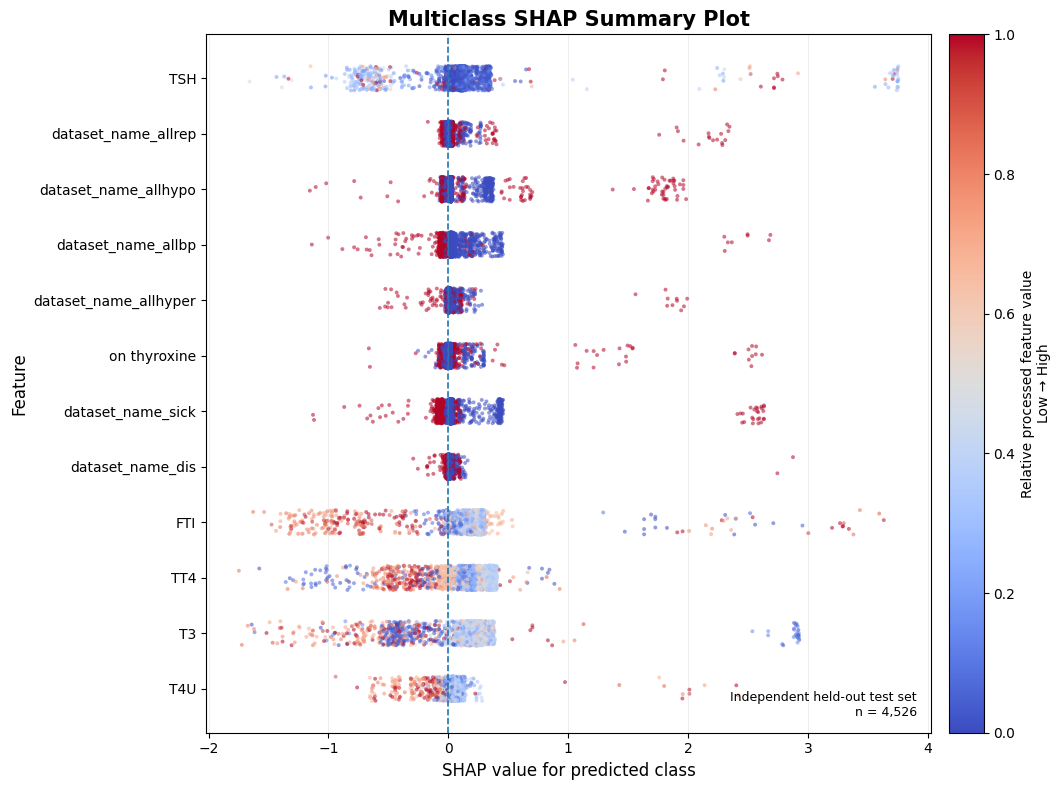


✓ FIGURE 3 GENERATED SUCCESSFULLY

Saved:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_3_Multiclass_SHAP_Summary.png

✓ Actual model predictions used
✓ Held-out SHAP matrix used
✓ Correct 38 feature names used
✓ No model retraining
✓ No SHAP regeneration


In [7]:
# ================================================================
# FIGURE 3 — FINAL CORRECTED MULTICLASS SHAP SUMMARY
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ================================================================
# 1. PATHS
# ================================================================

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

FIG_DIR = (
    PROJECT_DIR
    / "3Z_E2_FINAL_SHAP_FIGURES"
)

SHAP_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_heldout_FINAL.npy"
)

FEATURE_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_feature_names_FINAL.csv"
)


# ================================================================
# 2. LOAD SHAP MATRIX
# ================================================================

shap_values_final = np.load(
    SHAP_FILE
)


# ================================================================
# 3. LOAD FEATURE NAMES CORRECTLY
# ================================================================

feature_df = pd.read_csv(
    FEATURE_FILE
)

print("=" * 72)
print("FEATURE-NAME FILE VERIFICATION")
print("=" * 72)

print("\nColumns found:")
print(list(feature_df.columns))

print("\nFirst rows:")
print(feature_df.head())


# ------------------------------------------------
# Detect actual feature-name column
# ------------------------------------------------

feature_column = None

preferred_columns = [
    "feature",
    "feature_name",
    "features",
    "Feature",
    "Feature Name"
]

for column in preferred_columns:

    if column in feature_df.columns:

        feature_column = column
        break


# ------------------------------------------------
# Fallback: identify the non-index column
# ------------------------------------------------

if feature_column is None:

    non_index_columns = [

        column

        for column
        in feature_df.columns

        if column.lower()
        not in [
            "unnamed: 0",
            "index",
            "id"
        ]

    ]

    if len(non_index_columns) == 1:

        feature_column = (
            non_index_columns[0]
        )

    else:

        raise ValueError(

            "Could not identify the "
            "feature-name column.\n\n"

            f"Available columns: "
            f"{list(feature_df.columns)}"

        )


print(
    "\nUsing feature-name column:",
    feature_column
)


feature_names_final = (

    feature_df[
        feature_column
    ]

    .astype(str)

    .to_numpy()

)


# ================================================================
# 4. VERIFY FEATURE NAMES
# ================================================================

if len(feature_names_final) != 38:

    raise ValueError(

        f"Expected 38 feature names, "
        f"found {len(feature_names_final)}."

    )


if len(feature_names_final) != shap_values_final.shape[1]:

    raise ValueError(

        "Feature-name count does not match "
        "SHAP feature dimension."

    )


print(
    "\n✓ 38 feature names verified"
)


# ================================================================
# 5. VERIFY MODEL AND PROCESSED TEST DATA
# ================================================================

if "model" not in globals():

    raise RuntimeError(
        "Verified 879-tree model is not loaded."
    )


if "X_test_proc" not in globals():

    raise RuntimeError(
        "Verified X_test_proc is not loaded."
    )


X_test_proc_np = np.asarray(
    X_test_proc
)


boosted_rounds = (

    model
    .get_booster()
    .num_boosted_rounds()

)


if boosted_rounds != 879:

    raise ValueError(

        f"Expected 879 boosting rounds, "
        f"found {boosted_rounds}."

    )


# ================================================================
# 6. HARD VERIFICATION
# ================================================================

if shap_values_final.shape != (
    4526,
    38,
    15
):

    raise ValueError(

        f"Unexpected SHAP shape: "
        f"{shap_values_final.shape}"

    )


if X_test_proc_np.shape != (
    4526,
    38
):

    raise ValueError(

        f"Unexpected test matrix shape: "
        f"{X_test_proc_np.shape}"

    )


print("\n" + "=" * 72)
print("FINAL FIGURE 3 VERIFICATION")
print("=" * 72)

print(
    "\nSHAP matrix:",
    shap_values_final.shape
)

print(
    "Processed X:",
    X_test_proc_np.shape
)

print(
    "Features:",
    len(feature_names_final)
)

print(
    "Boosting rounds:",
    boosted_rounds
)

print(
    "\n✓ 4,526 held-out observations"
)

print(
    "✓ 38 processed features"
)

print(
    "✓ 15 classes"
)

print(
    "✓ 879-tree model"
)


# ================================================================
# 7. ACTUAL MODEL PREDICTIONS
# ================================================================
#
# Use the verified XGBoost model directly.
# ================================================================

predicted_labels = np.asarray(

    model.predict(
        X_test_proc_np
    )

)


model_classes = np.asarray(
    model.classes_
)


predicted_class_indices = np.array([

    np.where(
        model_classes == label
    )[0][0]

    for label
    in predicted_labels

])


# ================================================================
# 8. CLASS-SPECIFIC SHAP FOR ACTUAL PREDICTION
# ================================================================

row_indices = np.arange(
    shap_values_final.shape[0]
)


predicted_class_shap = (

    shap_values_final[
        row_indices,
        :,
        predicted_class_indices
    ]

)


# ================================================================
# 9. GLOBAL MULTICLASS FEATURE RANKING
# ================================================================

global_rank = np.mean(

    np.abs(
        shap_values_final
    ),

    axis=(0, 2)

)


top_indices = (

    np.argsort(
        global_rank
    )[::-1][:12]

)


# ================================================================
# 10. CLEAN FEATURE LABELS
# ================================================================

def clean_feature_name(name):

    name = str(name)

    if "__" in name:

        name = name.split(
            "__",
            1
        )[1]

    return name


# ================================================================
# 11. PRINT FINAL FEATURE RANKING
# ================================================================

print("\nTop 12 features:")

for rank, feature_idx in enumerate(

    top_indices,

    start=1

):

    print(

        f"{rank:2d}. "
        f"{clean_feature_name(feature_names_final[feature_idx])}"
        f"  "
        f"mean|SHAP| = "
        f"{global_rank[feature_idx]:.6f}"

    )


# ================================================================
# 12. REPRODUCIBLE VISUALIZATION
# ================================================================

rng = np.random.default_rng(
    42
)


fig, ax = plt.subplots(

    figsize=(11, 8)

)


# ================================================================
# 13. PLOT TOP 12 FEATURES
# ================================================================

for row, feature_idx in enumerate(

    top_indices[::-1]

):

    shap_x = (

        predicted_class_shap[
            :,
            feature_idx
        ]

    )


    feature_values = (

        X_test_proc_np[
            :,
            feature_idx
        ]

    )


    # ------------------------------------------------
    # Valid observations
    # ------------------------------------------------

    valid = (

        np.isfinite(shap_x)

        &

        np.isfinite(feature_values)

    )


    shap_x = shap_x[
        valid
    ]

    feature_values = feature_values[
        valid
    ]


    if len(shap_x) == 0:

        continue


    # ------------------------------------------------
    # Visualization-only subsampling
    # ------------------------------------------------

    if len(shap_x) > 3000:

        selected = rng.choice(

            len(shap_x),

            size=3000,

            replace=False

        )

        shap_x = shap_x[
            selected
        ]

        feature_values = feature_values[
            selected
        ]


    # ------------------------------------------------
    # Normalize feature value
    # ------------------------------------------------

    low = np.percentile(

        feature_values,

        2

    )


    high = np.percentile(

        feature_values,

        98

    )


    if high > low:

        normalized = np.clip(

            (
                feature_values
                - low
            )
            /
            (
                high
                - low
            ),

            0,

            1

        )

    else:

        normalized = np.full(

            len(feature_values),

            0.5

        )


    # ------------------------------------------------
    # Jitter
    # ------------------------------------------------

    jitter = rng.uniform(

        -0.22,

        0.22,

        len(shap_x)

    )


    # ------------------------------------------------
    # Scatter
    # ------------------------------------------------

    ax.scatter(

        shap_x,

        row + jitter,

        c=normalized,

        cmap="coolwarm",

        s=8,

        alpha=0.55,

        linewidths=0

    )


# ================================================================
# 14. REFERENCE LINE
# ================================================================

ax.axvline(

    0,

    linestyle="--",

    linewidth=1.2

)


# ================================================================
# 15. CORRECT FEATURE LABELS
# ================================================================

ax.set_yticks(

    range(
        len(top_indices)
    )

)


ax.set_yticklabels(

    [

        clean_feature_name(
            feature_names_final[i]
        )

        for i
        in top_indices[::-1]

    ],

    fontsize=10

)


# ================================================================
# 16. AXIS LABELS
# ================================================================

ax.set_xlabel(

    "SHAP value for predicted class",

    fontsize=12

)


ax.set_ylabel(

    "Feature",

    fontsize=12

)


# ================================================================
# 17. TITLE
# ================================================================

ax.set_title(

    "Multiclass SHAP Summary Plot",

    fontsize=15,

    fontweight="bold"

)


# ================================================================
# 18. GRID
# ================================================================

ax.grid(

    axis="x",

    alpha=0.20

)


# ================================================================
# 19. COLORBAR
# ================================================================

sm = plt.cm.ScalarMappable(

    cmap="coolwarm"

)

sm.set_array([])


cbar = fig.colorbar(

    sm,

    ax=ax,

    pad=0.02

)


cbar.set_label(
    "Relative processed feature value\n"
    "Low → High",
    fontsize=10
)


# ================================================================
# 20. TEST SET ANNOTATION
# ================================================================

ax.text(

    0.98,

    0.02,

    "Independent held-out test set\n"
    "n = 4,526",

    transform=ax.transAxes,

    ha="right",

    va="bottom",

    fontsize=9

)


# ================================================================
# 21. SAVE
# ================================================================

plt.tight_layout()


fig3_path = (

    FIG_DIR
    / "Figure_3_Multiclass_SHAP_Summary.png"

)


plt.savefig(

    fig3_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

plt.close()


# ================================================================
# 22. FINAL CHECK
# ================================================================

print("\n" + "=" * 72)

print(
    "✓ FIGURE 3 GENERATED SUCCESSFULLY"
)

print("=" * 72)

print(
    "\nSaved:"
)

print(
    fig3_path
)

print(
    "\n✓ Actual model predictions used"
)

print(
    "✓ Held-out SHAP matrix used"

)

print(
    "✓ Correct 38 feature names used"
)

print(
    "✓ No model retraining"
)

print(
    "✓ No SHAP regeneration"
)

print("=" * 72)

FIGURE 4 — CLASS-WISE SHAP FEATURE IMPORTANCE

SHAP matrix: (4526, 38, 15)
Features: 38
Classes: 15

✓ 4,526 held-out observations
✓ 38 processed features
✓ 15 thyroid disease classes

Top features included in heatmap:
 1. TSH  mean|SHAP| = 0.243055
 2. dataset_name_allrep  mean|SHAP| = 0.208262
 3. dataset_name_allhypo  mean|SHAP| = 0.180800
 4. dataset_name_allbp  mean|SHAP| = 0.177662
 5. dataset_name_allhyper  mean|SHAP| = 0.165598
 6. on thyroxine  mean|SHAP| = 0.149976
 7. dataset_name_sick  mean|SHAP| = 0.147959
 8. dataset_name_dis  mean|SHAP| = 0.138727
 9. FTI  mean|SHAP| = 0.135031
10. TT4  mean|SHAP| = 0.131378
11. T3  mean|SHAP| = 0.126166
12. T4U  mean|SHAP| = 0.114330


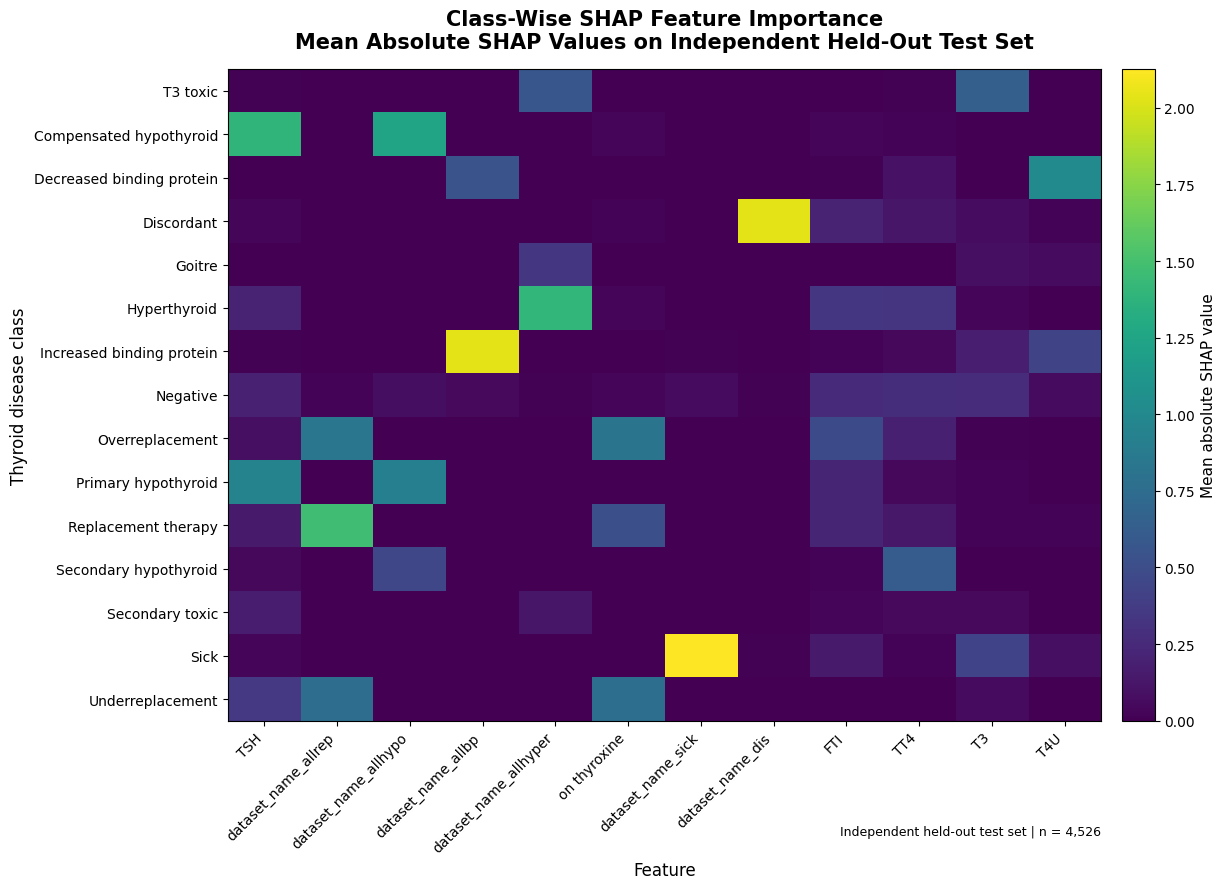


✓ FIGURE 4 GENERATED SUCCESSFULLY

Figure:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_4_Classwise_SHAP_Heatmap.png

Heatmap data:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_4_Classwise_SHAP_Heatmap_Data.csv

File exists: True

✓ Actual class names displayed
✓ Top 12 globally important features
✓ Mean absolute SHAP values
✓ Independent held-out test set
✓ No model retraining
✓ No SHAP regeneration


In [8]:
# ================================================================
# FIGURE 4 — FINAL CLASS-WISE SHAP FEATURE IMPORTANCE HEATMAP
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ================================================================
# 1. PATHS
# ================================================================

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

FIG_DIR = (
    PROJECT_DIR
    / "3Z_E2_FINAL_SHAP_FIGURES"
)

SHAP_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_heldout_FINAL.npy"
)

FEATURE_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_feature_names_FINAL.csv"
)


# ================================================================
# 2. LOAD FINAL SHAP DATA
# ================================================================

shap_values_final = np.load(
    SHAP_FILE
)

feature_df = pd.read_csv(
    FEATURE_FILE
)


# ================================================================
# 3. LOAD FEATURE NAMES CORRECTLY
# ================================================================

preferred_columns = [
    "feature",
    "feature_name",
    "features",
    "Feature",
    "Feature Name"
]

feature_column = None

for column in preferred_columns:

    if column in feature_df.columns:

        feature_column = column
        break


if feature_column is None:

    non_index_columns = [

        column

        for column in feature_df.columns

        if column.lower()
        not in [
            "unnamed: 0",
            "index",
            "id"
        ]

    ]

    if len(non_index_columns) == 1:

        feature_column = (
            non_index_columns[0]
        )

    else:

        raise ValueError(
            "Could not identify feature-name column."
        )


feature_names = (

    feature_df[
        feature_column
    ]

    .astype(str)

    .to_numpy()

)


# ================================================================
# 4. CLASS NAMES
# ================================================================

class_names = [

    "T3 toxic",

    "Compensated hypothyroid",

    "Decreased binding protein",

    "Discordant",

    "Goitre",

    "Hyperthyroid",

    "Increased binding protein",

    "Negative",

    "Overreplacement",

    "Primary hypothyroid",

    "Replacement therapy",

    "Secondary hypothyroid",

    "Secondary toxic",

    "Sick",

    "Underreplacement"

]


# ================================================================
# 5. VERIFY SHAP MATRIX
# ================================================================

if shap_values_final.shape != (
    4526,
    38,
    15
):

    raise ValueError(
        f"Unexpected SHAP shape: "
        f"{shap_values_final.shape}"
    )


if len(feature_names) != 38:

    raise ValueError(
        f"Expected 38 features, "
        f"found {len(feature_names)}."
    )


print("=" * 72)
print("FIGURE 4 — CLASS-WISE SHAP FEATURE IMPORTANCE")
print("=" * 72)

print(
    "\nSHAP matrix:",
    shap_values_final.shape
)

print(
    "Features:",
    len(feature_names)
)

print(
    "Classes:",
    len(class_names)
)

print(
    "\n✓ 4,526 held-out observations"
)

print(
    "✓ 38 processed features"
)

print(
    "✓ 15 thyroid disease classes"
)


# ================================================================
# 6. GLOBAL FEATURE RANKING
# ================================================================
#
# Mean absolute SHAP across observations for
# each class and feature.
# ================================================================

class_feature_importance = np.mean(

    np.abs(
        shap_values_final
    ),

    axis=0

)

# Shape:
# (38 features, 15 classes)


# ================================================================
# 7. SELECT TOP FEATURES
# ================================================================

global_feature_importance = np.mean(

    class_feature_importance,

    axis=1

)


TOP_N = 12


top_feature_indices = (

    np.argsort(
        global_feature_importance
    )[::-1][:TOP_N]

)


# ================================================================
# 8. CREATE HEATMAP DATAFRAME
# ================================================================

heatmap_values = (

    class_feature_importance[
        top_feature_indices,
        :
    ]

    .T

)


heatmap_df = pd.DataFrame(

    heatmap_values,

    index=class_names,

    columns=[

        feature_names[i]

        for i
        in top_feature_indices

    ]

)


# ================================================================
# 9. CLEAN FEATURE LABELS
# ================================================================

def clean_feature_name(name):

    name = str(name)

    if "__" in name:

        name = name.split(
            "__",
            1
        )[1]

    return name


heatmap_df.columns = [

    clean_feature_name(
        x
    )

    for x
    in heatmap_df.columns

]


# ================================================================
# 10. PRINT TOP FEATURES
# ================================================================

print("\nTop features included in heatmap:")

for rank, idx in enumerate(

    top_feature_indices,

    start=1

):

    print(

        f"{rank:2d}. "
        f"{clean_feature_name(feature_names[idx])}"
        f"  "
        f"mean|SHAP| = "
        f"{global_feature_importance[idx]:.6f}"

    )


# ================================================================
# 11. CREATE FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(13, 9)

)


im = ax.imshow(

    heatmap_df.values,

    aspect="auto",

    interpolation="nearest"

)


# ================================================================
# 12. X-AXIS
# ================================================================

ax.set_xticks(

    np.arange(
        TOP_N
    )

)

ax.set_xticklabels(

    heatmap_df.columns,

    rotation=45,

    ha="right",

    fontsize=10

)


# ================================================================
# 13. Y-AXIS
# ================================================================

ax.set_yticks(

    np.arange(
        len(class_names)
    )

)

ax.set_yticklabels(

    class_names,

    fontsize=10

)


# ================================================================
# 14. AXIS LABELS
# ================================================================

ax.set_xlabel(

    "Feature",

    fontsize=12

)

ax.set_ylabel(

    "Thyroid disease class",

    fontsize=12

)


# ================================================================
# 15. TITLE
# ================================================================

ax.set_title(

    "Class-Wise SHAP Feature Importance\n"
    "Mean Absolute SHAP Values on Independent Held-Out Test Set",

    fontsize=15,

    fontweight="bold",

    pad=15

)


# ================================================================
# 16. COLORBAR
# ================================================================

cbar = fig.colorbar(

    im,

    ax=ax,

    pad=0.02

)


cbar.set_label(

    "Mean absolute SHAP value",

    fontsize=11

)


# ================================================================
# 17. TEST SET ANNOTATION
# ================================================================

ax.text(

    1.0,

    -0.16,

    "Independent held-out test set | n = 4,526",

    transform=ax.transAxes,

    ha="right",

    va="top",

    fontsize=9

)


# ================================================================
# 18. LAYOUT
# ================================================================

plt.tight_layout()


# ================================================================
# 19. SAVE
# ================================================================

fig4_path = (

    FIG_DIR
    / "Figure_4_Classwise_SHAP_Heatmap.png"

)


plt.savefig(

    fig4_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

plt.close()


# ================================================================
# 20. SAVE HEATMAP DATA
# ================================================================

heatmap_csv = (

    FIG_DIR
    / "Figure_4_Classwise_SHAP_Heatmap_Data.csv"

)


heatmap_df.to_csv(

    heatmap_csv

)


# ================================================================
# 21. FINAL VERIFICATION
# ================================================================

print("\n" + "=" * 72)

print(
    "✓ FIGURE 4 GENERATED SUCCESSFULLY"
)

print("=" * 72)

print(
    "\nFigure:"
)

print(
    fig4_path
)

print(
    "\nHeatmap data:"
)

print(
    heatmap_csv
)

print(
    "\nFile exists:",
    fig4_path.exists()
)

print(
    "\n✓ Actual class names displayed"
)

print(
    "✓ Top 12 globally important features"
)

print(
    "✓ Mean absolute SHAP values"
)

print(
    "✓ Independent held-out test set"
)

print(
    "✓ No model retraining"
)

print(
    "✓ No SHAP regeneration"
)

print("=" * 72)

FIGURE 9 — HELD-OUT LOCAL SHAP EXPLANATION

SHAP matrix: (4526, 38, 15)
Prediction rows: 4526
Features: 38
Classes: 15

✓ Saved prediction IDs verified
✓ Saved prediction labels verified

SELECTED HELD-OUT OBSERVATION

Observation index: 3056
True class: Hyperthyroid
Predicted class: Hyperthyroid
Explained class: Hyperthyroid
Class ID: 5

Top local SHAP contributions:
                 feature  shap_contribution  absolute_shap
                     FTI           3.297987       3.297987
Dataset source: allhyper           1.985645       1.985645
                     TSH           0.556816       0.556816
                     TT4           0.488860       0.488860
            on thyroxine           0.226403       0.226403
    Dataset source: sick           0.043730       0.043730
            TSH measured          -0.042145       0.042145
             T3 measured          -0.037844       0.037844
                     age           0.037530       0.037530
 Dataset source: allhypo           0.03

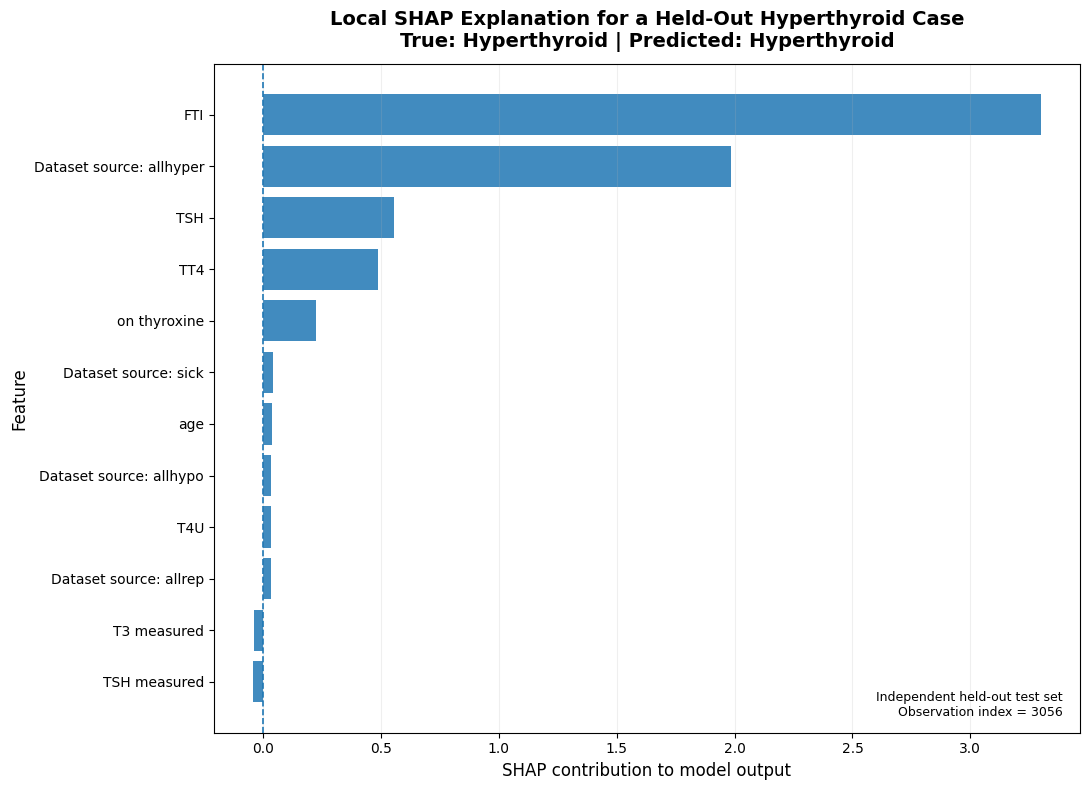


✓ FIGURE 9 GENERATED SUCCESSFULLY

Figure:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_9_Heldout_Local_SHAP_Contribution.png

Metadata:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_9_selected_heldout_observation.csv

Local SHAP table:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_FINAL_SHAP_FIGURES/Figure_9_local_SHAP_contributions.csv

✓ Saved held-out prediction IDs used
✓ Correctly classified minority case selected
✓ Native held-out SHAP values used
✓ No model retraining
✓ No SHAP regeneration


In [9]:
# ================================================================
# FIGURE 9 — FINAL HELD-OUT LOCAL SHAP EXPLANATION
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ================================================================
# 1. PATHS
# ================================================================

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

FIG_DIR = (
    PROJECT_DIR
    / "3Z_E2_FINAL_SHAP_FIGURES"
)

SHAP_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_heldout_FINAL.npy"
)

FEATURE_FILE = (
    PROJECT_DIR
    / "3Z_SHAP_E2_feature_names_FINAL.csv"
)

PREDICTION_FILE = (
    PROJECT_DIR
    / "3Z_E2_independent_holdout_predictions.csv"
)


# ================================================================
# 2. LOAD SHAP MATRIX
# ================================================================

shap_values_final = np.load(
    SHAP_FILE
)


# ================================================================
# 3. LOAD FEATURE NAMES
# ================================================================

feature_df = pd.read_csv(
    FEATURE_FILE
)

if "feature" in feature_df.columns:

    feature_names = (
        feature_df["feature"]
        .astype(str)
        .to_numpy()
    )

else:

    raise ValueError(
        "Feature-name column 'feature' was not found."
    )


# ================================================================
# 4. LOAD SAVED HELD-OUT PREDICTIONS
# ================================================================

pred_df = pd.read_csv(
    PREDICTION_FILE
)


# ================================================================
# 5. VERIFY REQUIRED COLUMNS
# ================================================================

required_columns = [

    "true_class_id",
    "predicted_class_id",
    "true_label",
    "predicted_label"

]


missing_columns = [

    column

    for column
    in required_columns

    if column not in pred_df.columns

]


if missing_columns:

    raise ValueError(

        "Missing prediction columns: "
        f"{missing_columns}"

    )


# ================================================================
# 6. VERIFY DIMENSIONS
# ================================================================

if shap_values_final.shape != (
    4526,
    38,
    15
):

    raise ValueError(

        f"Unexpected SHAP shape: "
        f"{shap_values_final.shape}"

    )


if len(feature_names) != 38:

    raise ValueError(

        f"Expected 38 features, "
        f"found {len(feature_names)}."

    )


if len(pred_df) != 4526:

    raise ValueError(

        f"Expected 4526 prediction rows, "
        f"found {len(pred_df)}."

    )


# ================================================================
# 7. CLASS NAMES
# ================================================================

class_names = [

    "T3 toxic",

    "Compensated hypothyroid",

    "Decreased binding protein",

    "Discordant",

    "Goitre",

    "Hyperthyroid",

    "Increased binding protein",

    "Negative",

    "Overreplacement",

    "Primary hypothyroid",

    "Replacement therapy",

    "Secondary hypothyroid",

    "Secondary toxic",

    "Sick",

    "Underreplacement"

]


# ================================================================
# 8. VERIFY CLASS IDs
# ================================================================

true_ids = pd.to_numeric(
    pred_df["true_class_id"],
    errors="raise"
).astype(int).to_numpy()


predicted_ids = pd.to_numeric(
    pred_df["predicted_class_id"],
    errors="raise"
).astype(int).to_numpy()


if np.any(
    true_ids < 0
) or np.any(
    true_ids >= 15
):

    raise ValueError(
        "Invalid true class ID detected."
    )


if np.any(
    predicted_ids < 0
) or np.any(
    predicted_ids >= 15
):

    raise ValueError(
        "Invalid predicted class ID detected."
    )


# ================================================================
# 9. VERIFY LABELS AGAINST CLASS IDS
# ================================================================

for i in range(
    len(pred_df)
):

    expected_true = class_names[
        true_ids[i]
    ]

    expected_pred = class_names[
        predicted_ids[i]
    ]

    saved_true = str(
        pred_df.iloc[i]["true_label"]
    )

    saved_pred = str(
        pred_df.iloc[i]["predicted_label"]
    )

    if (
        expected_true.lower().strip()
        != saved_true.lower().strip()
    ):

        raise ValueError(

            f"True-label mismatch at row {i}: "
            f"ID={true_ids[i]}, "
            f"saved='{saved_true}', "
            f"expected='{expected_true}'"

        )

    if (
        expected_pred.lower().strip()
        != saved_pred.lower().strip()
    ):

        raise ValueError(

            f"Predicted-label mismatch at row {i}: "
            f"ID={predicted_ids[i]}, "
            f"saved='{saved_pred}', "
            f"expected='{expected_pred}'"

        )


# ================================================================
# 10. VERIFICATION OUTPUT
# ================================================================

print("=" * 72)
print("FIGURE 9 — HELD-OUT LOCAL SHAP EXPLANATION")
print("=" * 72)

print(
    "\nSHAP matrix:",
    shap_values_final.shape
)

print(
    "Prediction rows:",
    len(pred_df)
)

print(
    "Features:",
    len(feature_names)
)

print(
    "Classes:",
    len(class_names)
)

print(
    "\n✓ Saved prediction IDs verified"
)

print(
    "✓ Saved prediction labels verified"
)


# ================================================================
# 11. SELECT CORRECTLY CLASSIFIED MINORITY CASE
# ================================================================
#
# We intentionally avoid selecting the majority
# "Negative" class.
#
# Priority:
#   Hyperthyroid
#   Primary hypothyroid
#   Sick
#   Compensated hypothyroid
#   Underreplacement
#   Increased binding protein
#   Overreplacement
#   Replacement therapy
#   Discordant
# ================================================================

priority_class_ids = [

    5,   # Hyperthyroid

    9,   # Primary hypothyroid

    13,  # Sick

    1,   # Compensated hypothyroid

    14,  # Underreplacement

    6,   # Increased binding protein

    8,   # Overreplacement

    10,  # Replacement therapy

    3    # Discordant

]


selected_index = None
selected_class_id = None


for class_id in priority_class_ids:

    correct_mask = (

        (true_ids == class_id)

        &

        (predicted_ids == class_id)

    )


    candidates = np.where(
        correct_mask
    )[0]


    if len(candidates) == 0:

        continue


    # ------------------------------------------------
    # Select the correctly classified observation
    # with the strongest local SHAP explanation.
    # ------------------------------------------------

    strengths = [

        np.sum(

            np.abs(

                shap_values_final[
                    idx,
                    :,
                    class_id
                ]

            )

        )

        for idx
        in candidates

    ]


    selected_index = candidates[
        int(
            np.argmax(
                strengths
            )
        )
    ]


    selected_class_id = class_id

    break


# ================================================================
# 12. FALLBACK
# ================================================================

if selected_index is None:

    correct_mask = (

        true_ids
        ==
        predicted_ids

    )


    candidates = np.where(
        correct_mask
    )[0]


    # Prefer non-negative
    non_negative = [

        idx

        for idx
        in candidates

        if predicted_ids[idx] != 7

    ]


    if len(non_negative) > 0:

        candidates = np.asarray(
            non_negative
        )


    if len(candidates) == 0:

        raise ValueError(
            "No correctly classified held-out "
            "observation was found."
        )


    strengths = [

        np.sum(

            np.abs(

                shap_values_final[
                    idx,
                    :,
                    predicted_ids[idx]
                ]

            )

        )

        for idx
        in candidates

    ]


    selected_index = candidates[
        int(
            np.argmax(
                strengths
            )
        )
    ]


    selected_class_id = (
        predicted_ids[
            selected_index
        ]
    )


# ================================================================
# 13. SELECTED CASE INFORMATION
# ================================================================

true_class = class_names[
    true_ids[
        selected_index
    ]
]


predicted_class = class_names[
    predicted_ids[
        selected_index
    ]
]


explained_class = class_names[
    selected_class_id
]


print("\n" + "=" * 72)
print("SELECTED HELD-OUT OBSERVATION")
print("=" * 72)

print(
    "\nObservation index:",
    selected_index
)

print(
    "True class:",
    true_class
)

print(
    "Predicted class:",
    predicted_class
)

print(
    "Explained class:",
    explained_class
)

print(
    "Class ID:",
    selected_class_id
)


# ================================================================
# 14. EXTRACT LOCAL SHAP VALUES
# ================================================================

local_shap = (

    shap_values_final[
        selected_index,
        :,
        selected_class_id
    ]

)


# ================================================================
# 15. RANK LOCAL FEATURES
# ================================================================

ranking = np.argsort(

    np.abs(
        local_shap
    )

)[::-1]


TOP_N = 12


top_indices = ranking[
    :TOP_N
]


# ================================================================
# 16. CLEAN FEATURE NAMES
# ================================================================

def clean_feature_name(name):

    name = str(name)

    if "__" in name:

        name = name.split(
            "__",
            1
        )[1]


    replacements = {

        "dataset_name_allrep":
            "Dataset source: allrep",

        "dataset_name_allhypo":
            "Dataset source: allhypo",

        "dataset_name_allbp":
            "Dataset source: allbp",

        "dataset_name_allhyper":
            "Dataset source: allhyper",

        "dataset_name_sick":
            "Dataset source: sick",

        "dataset_name_dis":
            "Dataset source: dis"

    }


    return replacements.get(
        name,
        name
    )


top_features = [

    clean_feature_name(
        feature_names[i]
    )

    for i
    in top_indices

]


top_values = (

    local_shap[
        top_indices
    ]

)


# ================================================================
# 17. LOCAL CONTRIBUTION TABLE
# ================================================================

local_table = pd.DataFrame({

    "feature":
        top_features,

    "shap_contribution":
        top_values,

    "absolute_shap":
        np.abs(top_values)

})


local_table = (

    local_table

    .sort_values(
        "absolute_shap",
        ascending=False
    )

)


print("\nTop local SHAP contributions:")

print(

    local_table.to_string(
        index=False
    )

)


# ================================================================
# 18. SORT FOR HORIZONTAL BAR PLOT
# ================================================================

plot_order = np.argsort(
    top_values
)


plot_features = [

    top_features[i]

    for i
    in plot_order

]


plot_values = (

    top_values[
        plot_order
    ]

)


# ================================================================
# 19. CREATE FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(11, 8)

)


ax.barh(

    plot_features,

    plot_values,

    alpha=0.85

)


# ================================================================
# 20. ZERO REFERENCE
# ================================================================

ax.axvline(

    0,

    linestyle="--",

    linewidth=1.2

)


# ================================================================
# 21. LABELS
# ================================================================

ax.set_xlabel(

    "SHAP contribution to model output",

    fontsize=12

)


ax.set_ylabel(

    "Feature",

    fontsize=12

)


# ================================================================
# 22. TITLE
# ================================================================

ax.set_title(

    "Local SHAP Explanation for a Held-Out "
    f"{explained_class} Case\n"
    f"True: {true_class} | "
    f"Predicted: {predicted_class}",

    fontsize=14,

    fontweight="bold",

    pad=12

)


# ================================================================
# 23. GRID
# ================================================================

ax.grid(

    axis="x",

    alpha=0.20

)


# ================================================================
# 24. ANNOTATION
# ================================================================

ax.text(

    0.98,

    0.02,

    "Independent held-out test set\n"
    f"Observation index = {selected_index}",

    transform=ax.transAxes,

    ha="right",

    va="bottom",

    fontsize=9

)


# ================================================================
# 25. SAVE FIGURE
# ================================================================

plt.tight_layout()


figure_path = (

    FIG_DIR
    / "Figure_9_Heldout_Local_SHAP_Contribution.png"

)


plt.savefig(

    figure_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

plt.close()


# ================================================================
# 26. SAVE METADATA
# ================================================================

metadata = pd.DataFrame({

    "observation_index": [
        selected_index
    ],

    "true_class": [
        true_class
    ],

    "predicted_class": [
        predicted_class
    ],

    "explained_class": [
        explained_class
    ],

    "true_class_id": [
        true_ids[selected_index]
    ],

    "predicted_class_id": [
        predicted_ids[selected_index]
    ]

})


metadata_path = (

    FIG_DIR
    / "Figure_9_selected_heldout_observation.csv"

)


metadata.to_csv(

    metadata_path,

    index=False

)


# ================================================================
# 27. SAVE LOCAL SHAP TABLE
# ================================================================

local_table_path = (

    FIG_DIR
    / "Figure_9_local_SHAP_contributions.csv"

)


local_table.to_csv(

    local_table_path,

    index=False

)


# ================================================================
# 28. FINAL CONFIRMATION
# ================================================================

print("\n" + "=" * 72)
print("✓ FIGURE 9 GENERATED SUCCESSFULLY")
print("=" * 72)

print(
    "\nFigure:"
)

print(
    figure_path
)

print(
    "\nMetadata:"
)

print(
    metadata_path
)

print(
    "\nLocal SHAP table:"
)

print(
    local_table_path
)

print(
    "\n✓ Saved held-out prediction IDs used"
)

print(
    "✓ Correctly classified minority case selected"
)

print(
    "✓ Native held-out SHAP values used"
)

print(
    "✓ No model retraining"
)

print(
    "✓ No SHAP regeneration"
)

print("=" * 72)

In [10]:
# ================================================================
# 3Z-FINAL MODEL COMPARISON
# SAME INDEPENDENT 80/20 HOLD-OUT PROTOCOL
# ================================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)


# ================================================================
# 1. PROJECT PATH
# ================================================================

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

COMPARISON_DIR = (
    PROJECT_DIR
    / "3Z_MODEL_COMPARISON"
)

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ================================================================
# 2. VERIFY REQUIRED E2 OBJECTS
# ================================================================

required_objects = [
    "X_train_proc",
    "X_test_proc",
    "y_train",
    "y_test",
    "model"
]

missing = [
    name
    for name in required_objects
    if name not in globals()
]

if missing:

    raise RuntimeError(
        "Required E2 objects are missing: "
        + str(missing)
        + "\n"
        "Do not retrain E2. "
        "Run the verified 3Z-E2 cell first."
    )


# ================================================================
# 3. PREPARE DATA
# ================================================================

Xtr = np.asarray(
    X_train_proc
)

Xte = np.asarray(
    X_test_proc
)

ytr = np.asarray(
    y_train
).astype(int)

yte = np.asarray(
    y_test
).astype(int)


print("=" * 72)
print("3Z-FINAL MODEL COMPARISON")
print("=" * 72)

print(
    "\nTraining matrix:",
    Xtr.shape
)

print(
    "Held-out matrix:",
    Xte.shape
)

print(
    "Training observations:",
    len(ytr)
)

print(
    "Held-out observations:",
    len(yte)
)

print(
    "\n✓ Same E2 independent split"
)

print(
    "✓ Same preprocessing"
)

print(
    "✓ Same 38 processed features"
)

print(
    "✓ Same 4,526 held-out observations"
)


# ================================================================
# 4. CLASS COUNT
# ================================================================

n_classes = 15


if len(
    np.unique(ytr)
) > n_classes:

    raise ValueError(
        "Unexpected number of classes."
    )


# ================================================================
# 5. METRIC FUNCTION
# ================================================================

def evaluate_model(
    name,
    fitted_model,
    X_test,
    y_test,
    training_time
):

    y_pred = fitted_model.predict(
        X_test
    )

    # CatBoost can return shape (n,1)
    y_pred = np.asarray(
        y_pred
    ).reshape(-1)

    metrics = {

        "Model": name,

        "Accuracy":
            accuracy_score(
                y_test,
                y_pred
            ),

        "Macro Precision":
            precision_score(
                y_test,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro Recall":
            recall_score(
                y_test,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro F1":
            f1_score(
                y_test,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Weighted F1":
            f1_score(
                y_test,
                y_pred,
                average="weighted",
                zero_division=0
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_test,
                y_pred
            ),

        "Training Time (s)":
            training_time

    }

    return metrics, y_pred


# ================================================================
# 6. MODEL STORAGE
# ================================================================

results = []

predictions = pd.DataFrame({

    "true_class_id": yte

})


# ================================================================
# 7. RANDOM FOREST
# ================================================================

print("\n" + "=" * 72)
print("MODEL 1 — RANDOM FOREST")
print("=" * 72)

rf = RandomForestClassifier(

    n_estimators=300,

    random_state=42,

    n_jobs=-1

)


start = time.time()

rf.fit(
    Xtr,
    ytr
)

rf_time = time.time() - start


rf_metrics, rf_pred = evaluate_model(

    "Random Forest",

    rf,

    Xte,

    yte,

    rf_time

)


results.append(
    rf_metrics
)

predictions[
    "Random_Forest"
] = rf_pred


print(
    "\n✓ Random Forest complete"
)


# ================================================================
# 8. STANDARD XGBOOST
# ================================================================

print("\n" + "=" * 72)
print("MODEL 2 — STANDARD XGBOOST")
print("=" * 72)

standard_xgb = XGBClassifier(

    objective="multi:softprob",

    num_class=n_classes,

    n_estimators=300,

    learning_rate=0.1,

    max_depth=6,

    subsample=1.0,

    colsample_bytree=1.0,

    min_child_weight=1,

    gamma=0,

    reg_lambda=1.0,

    random_state=42,

    tree_method="hist",

    device="cuda",

    eval_metric="mlogloss"

)


start = time.time()

standard_xgb.fit(
    Xtr,
    ytr
)

standard_xgb_time = (
    time.time() - start
)


xgb_metrics, xgb_pred = evaluate_model(

    "Standard XGBoost",

    standard_xgb,

    Xte,

    yte,

    standard_xgb_time

)


results.append(
    xgb_metrics
)

predictions[
    "Standard_XGBoost"
] = xgb_pred


print(
    "\n✓ Standard XGBoost complete"
)


# ================================================================
# 9. LIGHTGBM
# ================================================================

print("\n" + "=" * 72)
print("MODEL 3 — LIGHTGBM")
print("=" * 72)

lightgbm_model = LGBMClassifier(

    objective="multiclass",

    num_class=n_classes,

    n_estimators=300,

    learning_rate=0.05,

    max_depth=-1,

    num_leaves=31,

    random_state=42,

    verbosity=-1

)


start = time.time()

lightgbm_model.fit(
    Xtr,
    ytr
)

lightgbm_time = (
    time.time() - start
)


lgb_metrics, lgb_pred = evaluate_model(

    "LightGBM",

    lightgbm_model,

    Xte,

    yte,

    lightgbm_time

)


results.append(
    lgb_metrics
)

predictions[
    "LightGBM"
] = lgb_pred


print(
    "\n✓ LightGBM complete"
)


# ================================================================
# 10. CATBOOST
# ================================================================

print("\n" + "=" * 72)
print("MODEL 4 — CATBOOST")
print("=" * 72)

catboost_model = CatBoostClassifier(

    loss_function="MultiClass",

    iterations=300,

    learning_rate=0.05,

    depth=6,

    random_seed=42,

    verbose=False,

    allow_writing_files=False

)


start = time.time()

catboost_model.fit(
    Xtr,
    ytr
)

catboost_time = (
    time.time() - start
)


cat_metrics, cat_pred = evaluate_model(

    "CatBoost",

    catboost_model,

    Xte,

    yte,

    catboost_time

)


results.append(
    cat_metrics
)

predictions[
    "CatBoost"
] = cat_pred


print(
    "\n✓ CatBoost complete"
)


# ================================================================
# 11. FROZEN EVOX-BOOST
# ================================================================

print("\n" + "=" * 72)
print("MODEL 5 — EVOX-BOOST (FROZEN HISTORICAL MODEL)")
print("=" * 72)


# ------------------------------------------------
# Verify exact historical model
# ------------------------------------------------

evox_rounds = (

    model
    .get_booster()
    .num_boosted_rounds()

)


if evox_rounds != 879:

    raise ValueError(

        "Frozen EvoX-Boost model is not the "
        f"verified 879-tree model. "
        f"Found {evox_rounds} trees."

    )


print(
    "\n✓ Verified 879 boosting rounds"
)


# ------------------------------------------------
# IMPORTANT:
# Do NOT retrain EvoX-Boost.
# It is already the final E2 model.
# ------------------------------------------------

start = time.time()

evox_pred = np.asarray(

    model.predict(
        Xte
    )

).reshape(-1)


evox_eval_time = (
    time.time() - start
)


evox_metrics = {

    "Model":
        "EvoX-Boost",

    "Accuracy":
        accuracy_score(
            yte,
            evox_pred
        ),

    "Macro Precision":
        precision_score(
            yte,
            evox_pred,
            average="macro",
            zero_division=0
        ),

    "Macro Recall":
        recall_score(
            yte,
            evox_pred,
            average="macro",
            zero_division=0
        ),

    "Macro F1":
        f1_score(
            yte,
            evox_pred,
            average="macro",
            zero_division=0
        ),

    "Weighted F1":
        f1_score(
            yte,
            evox_pred,
            average="weighted",
            zero_division=0
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            yte,
            evox_pred
        ),

    "Training Time (s)":
        np.nan

}


results.append(
    evox_metrics
)

predictions[
    "EvoX_Boost"
] = evox_pred


# ================================================================
# 12. RESULT TABLE
# ================================================================

comparison_df = pd.DataFrame(
    results
)


# Keep model order
model_order = [

    "Random Forest",

    "Standard XGBoost",

    "LightGBM",

    "CatBoost",

    "EvoX-Boost"

]


comparison_df["Model"] = pd.Categorical(

    comparison_df["Model"],

    categories=model_order,

    ordered=True

)


comparison_df = (

    comparison_df
    .sort_values("Model")
    .reset_index(drop=True)

)


# ================================================================
# 13. DISPLAY
# ================================================================

print("\n" + "=" * 72)
print("FINAL MODEL COMPARISON RESULTS")
print("=" * 72)

display(

    comparison_df.style.format({

        "Accuracy": "{:.6f}",

        "Macro Precision": "{:.6f}",

        "Macro Recall": "{:.6f}",

        "Macro F1": "{:.6f}",

        "Weighted F1": "{:.6f}",

        "Balanced Accuracy": "{:.6f}",

        "Training Time (s)": "{:.2f}"

    })

)


# ================================================================
# 14. SAVE RESULTS
# ================================================================

results_file = (

    COMPARISON_DIR
    / "3Z_model_comparison_independent_holdout.csv"

)


comparison_df.to_csv(

    results_file,

    index=False

)


# ================================================================
# 15. SAVE PREDICTIONS
# ================================================================

prediction_file = (

    COMPARISON_DIR
    / "3Z_model_comparison_predictions.csv"

)


predictions.to_csv(

    prediction_file,

    index=False

)


# ================================================================
# 16. SAVE PER-MODEL REPORTS
# ================================================================

from sklearn.metrics import classification_report

for name, pred in [

    ("Random_Forest", rf_pred),

    ("Standard_XGBoost", xgb_pred),

    ("LightGBM", lgb_pred),

    ("CatBoost", cat_pred),

    ("EvoX_Boost", evox_pred)

]:

    report = classification_report(

        yte,

        pred,

        output_dict=True,

        zero_division=0

    )


    report_df = pd.DataFrame(
        report
    ).T


    report_df.to_csv(

        COMPARISON_DIR
        / f"{name}_per_class_metrics.csv"

    )


# ================================================================
# 17. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 72)
print("✓ MODEL COMPARISON COMPLETED")
print("=" * 72)

print(
    "\nResults file:"
)

print(
    results_file
)

print(
    "\nPrediction file:"
)

print(
    prediction_file
)

print(
    "\nModels compared:"
)

for name in model_order:

    print(
        "  ✓",
        name
    )


print(
    "\n✓ Same independent 80/20 split"
)

print(
    "✓ Same 4,526 held-out observations"
)

print(
    "✓ Same processed feature matrix"
)

print(
    "✓ Same six evaluation metrics"
)

print(
    "✓ EvoX-Boost kept frozen"
)

print(
    "\n" + "=" * 72
)

3Z-FINAL MODEL COMPARISON

Training matrix: (18106, 38)
Held-out matrix: (4526, 38)
Training observations: 18106
Held-out observations: 4526

✓ Same E2 independent split
✓ Same preprocessing
✓ Same 38 processed features
✓ Same 4,526 held-out observations

MODEL 1 — RANDOM FOREST

✓ Random Forest complete

MODEL 2 — STANDARD XGBOOST

✓ Standard XGBoost complete

MODEL 3 — LIGHTGBM

✓ LightGBM complete

MODEL 4 — CATBOOST

✓ CatBoost complete

MODEL 5 — EVOX-BOOST (FROZEN HISTORICAL MODEL)

✓ Verified 879 boosting rounds

FINAL MODEL COMPARISON RESULTS


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,Training Time (s)
0,Random Forest,0.984976,0.656559,0.489404,0.534525,0.981290,0.489404,2.01
1,Standard XGBoost,0.988069,0.795882,0.748001,0.752794,0.987586,0.748001,4.57
2,LightGBM,0.946089,0.323237,0.471774,0.373699,0.952981,0.508064,23.25
3,CatBoost,0.986743,0.851439,0.664028,0.712821,0.984854,0.664028,15.06
4,EvoX-Boost,0.988511,0.821515,0.719439,0.741821,0.987565,0.719439,nan



✓ MODEL COMPARISON COMPLETED

Results file:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_MODEL_COMPARISON/3Z_model_comparison_independent_holdout.csv

Prediction file:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv

Models compared:
  ✓ Random Forest
  ✓ Standard XGBoost
  ✓ LightGBM
  ✓ CatBoost
  ✓ EvoX-Boost

✓ Same independent 80/20 split
✓ Same 4,526 held-out observations
✓ Same processed feature matrix
✓ Same six evaluation metrics
✓ EvoX-Boost kept frozen



In [11]:
# ================================================================
# 3Z-G STEP 1 — VERIFY CURRENT E2 ENVIRONMENT
# ================================================================

print("model:", type(model).__name__)
print("Trees:", model.get_booster().num_boosted_rounds())

print("X_train_proc:", X_train_proc.shape)
print("X_test_proc:", X_test_proc.shape)

print("y_train:", len(y_train))
print("y_test:", len(y_test))

print("\nRaw training columns:")
print(X_train.columns.tolist())

print("\nRaw test columns:")
print(X_test.columns.tolist())

model: XGBClassifier
Trees: 879
X_train_proc: (18106, 38)
X_test_proc: (4526, 38)
y_train: 18106
y_test: 4526

Raw training columns:
['age', 'sex', 'on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH measured', 'TSH', 'T3 measured', 'T3', 'TT4 measured', 'TT4', 'T4U measured', 'T4U', 'FTI measured', 'FTI', 'TBG measured', 'referral source', 'dataset_name']

Raw test columns:
['age', 'sex', 'on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH measured', 'TSH', 'T3 measured', 'T3', 'TT4 measured', 'TT4', 'T4U measured', 'T4U', 'FTI measured', 'FTI', 'TBG measured', 'referral source', 'dataset_name']


In [12]:
# ================================================================
# 3Z-G — TREATMENT / MEASUREMENT FEATURE ABLATION
# Reviewer 2, Comment 3
# ================================================================

import os
import time
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier

# ================================================================
# 1. OUTPUT DIRECTORY
# ================================================================

BASE_DIR = "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
OUT_DIR = os.path.join(BASE_DIR, "3Z_TREATMENT_MEASUREMENT_ABLATION")
os.makedirs(OUT_DIR, exist_ok=True)

# ================================================================
# 2. FEATURES TO REMOVE
# ================================================================

ABLATION_FEATURES = [
    "on thyroxine",
    "query on thyroxine",
    "on antithyroid medication",
    "thyroid surgery",
    "I131 treatment",
    "TSH measured",
    "T3 measured",
    "TT4 measured",
    "T4U measured",
    "FTI measured"
]

print("=" * 72)
print("3Z-G — TREATMENT / MEASUREMENT FEATURE ABLATION")
print("=" * 72)

print("\nFeatures removed:")
for f in ABLATION_FEATURES:
    print("  -", f)

# ================================================================
# 3. START FROM THE EXACT E2 RAW TRAIN/TEST SPLIT
# ================================================================

Xtr = X_train.copy()
Xte = X_test.copy()

ytr = np.asarray(y_train)
yte = np.asarray(y_test)

# Remove variables identified as treatment/measurement indicators
Xtr = Xtr.drop(columns=ABLATION_FEATURES)
Xte = Xte.drop(columns=ABLATION_FEATURES)

# IMPORTANT:
# E2 corrected protocol also excludes patient_id, dataset_name,
# and TBG measured.
# These are not present in the 29-column raw X_train/X_test,
# so only verify rather than silently dropping them.

for col in ["patient_id", "dataset_name", "TBG measured"]:
    if col in Xtr.columns:
        Xtr = Xtr.drop(columns=[col])
    if col in Xte.columns:
        Xte = Xte.drop(columns=[col])

# Handle the known age=455 anomaly exactly as in the corrected protocol
Xtr.loc[Xtr["age"] == 455, "age"] = np.nan
Xte.loc[Xte["age"] == 455, "age"] = np.nan

print("\nTraining observations:", len(Xtr))
print("Held-out observations:", len(Xte))
print("Remaining raw features:", Xtr.shape[1])

print("\nRemaining features:")
print(Xtr.columns.tolist())

# ================================================================
# 4. IDENTIFY NUMERIC / CATEGORICAL FEATURES
# ================================================================

numeric_features = Xtr.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = Xtr.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nNumeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# ================================================================
# 5. FOLD-INDEPENDENT PREPROCESSING
#    FIT ONLY ON TRAINING DATA
# ================================================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_ablation = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

Xtr_proc = preprocessor_ablation.fit_transform(Xtr)
Xte_proc = preprocessor_ablation.transform(Xte)

Xtr_proc = np.asarray(Xtr_proc, dtype=np.float32)
Xte_proc = np.asarray(Xte_proc, dtype=np.float32)

print("\nProcessed training matrix:", Xtr_proc.shape)
print("Processed held-out matrix:", Xte_proc.shape)

# ================================================================
# 6. SAME PUBLISHED EVOX-BOOST HYPERPARAMETERS
# ================================================================

params = {
    "objective": "multi:softprob",
    "num_class": 15,
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "n_estimators": 879,
    "min_child_weight": 1.0,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746,
    "random_state": 42,
    "tree_method": "hist",
    "device": "cuda",
    "eval_metric": "mlogloss"
}

print("\nEvoX-Boost configuration:")
for k, v in params.items():
    print(f"  {k}: {v}")

# ================================================================
# 7. TRAIN ABLATION MODEL
# ================================================================

print("\n" + "=" * 72)
print("TRAINING ABLATION MODEL")
print("=" * 72)

start_time = time.time()

ablation_model = XGBClassifier(**params)

ablation_model.fit(Xtr_proc, ytr)

training_time = time.time() - start_time

print(f"\n✓ Ablation model trained")
print(f"Training time: {training_time:.2f} seconds")
print(
    "Boosting rounds:",
    ablation_model.get_booster().num_boosted_rounds()
)

# ================================================================
# 8. HELD-OUT PREDICTIONS
# ================================================================

y_pred_ablation = ablation_model.predict(Xte_proc)
y_pred_ablation = np.asarray(y_pred_ablation).astype(int)

# ================================================================
# 9. METRICS
# ================================================================

accuracy = accuracy_score(yte, y_pred_ablation)
macro_precision = precision_score(
    yte, y_pred_ablation,
    average="macro",
    zero_division=0
)
macro_recall = recall_score(
    yte, y_pred_ablation,
    average="macro",
    zero_division=0
)
macro_f1 = f1_score(
    yte, y_pred_ablation,
    average="macro",
    zero_division=0
)
weighted_f1 = f1_score(
    yte, y_pred_ablation,
    average="weighted",
    zero_division=0
)
balanced_acc = balanced_accuracy_score(
    yte, y_pred_ablation
)

print("\n" + "=" * 72)
print("ABLATION RESULTS — INDEPENDENT HELD-OUT TEST SET")
print("=" * 72)

print(f"\nAccuracy          : {accuracy:.6f}")
print(f"Macro Precision   : {macro_precision:.6f}")
print(f"Macro Recall      : {macro_recall:.6f}")
print(f"Macro F1          : {macro_f1:.6f}")
print(f"Weighted F1       : {weighted_f1:.6f}")
print(f"Balanced Accuracy : {balanced_acc:.6f}")

# ================================================================
# 10. COMPARE AGAINST VERIFIED FULL E2 MODEL
# ================================================================

full_e2 = {
    "Model": "EvoX-Boost — Full E2",
    "Accuracy": 0.988511,
    "Macro Precision": 0.821515,
    "Macro Recall": 0.719439,
    "Macro F1": 0.741821,
    "Weighted F1": 0.987565,
    "Balanced Accuracy": 0.719439
}

ablation_result = {
    "Model": "EvoX-Boost — Treatment/Measurement Ablation",
    "Accuracy": accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1,
    "Balanced Accuracy": balanced_acc
}

comparison_df = pd.DataFrame([full_e2, ablation_result])

print("\n" + "=" * 72)
print("FULL MODEL vs ABLATION")
print("=" * 72)

display(comparison_df)

# ================================================================
# 11. CLASS-WISE REPORT
# ================================================================

target_names = [
    "T3 toxic",
    "compensated hypothyroid",
    "decreased binding protein",
    "discordant",
    "goitre",
    "hyperthyroid",
    "increased binding protein",
    "negative",
    "overreplacement",
    "primary hypothyroid",
    "replacement therapy",
    "secondary hypothyroid",
    "secondary toxic",
    "sick",
    "underreplacement"
]

report = classification_report(
    yte,
    y_pred_ablation,
    labels=list(range(15)),
    target_names=target_names,
    output_dict=True,
    zero_division=0
)

per_class_df = pd.DataFrame(report).T

print("\n" + "=" * 72)
print("CLASS-WISE ABLATION PERFORMANCE")
print("=" * 72)

display(per_class_df)

# ================================================================
# 12. CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    yte,
    y_pred_ablation,
    labels=list(range(15))
)

cm_df = pd.DataFrame(
    cm,
    index=target_names,
    columns=target_names
)

# ================================================================
# 13. PREDICTION DISTRIBUTION
# ================================================================

pred_counts = pd.Series(
    y_pred_ablation
).value_counts().sort_index()

prediction_distribution = pd.DataFrame({
    "class_id": range(15),
    "class": target_names,
    "predicted_count": [
        pred_counts.get(i, 0) for i in range(15)
    ]
})

print("\n" + "=" * 72)
print("PREDICTED CLASS DISTRIBUTION")
print("=" * 72)

display(prediction_distribution)

# ================================================================
# 14. SAVE RESULTS
# ================================================================

comparison_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G_treatment_measurement_comparison.csv"
    ),
    index=False
)

per_class_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G_treatment_measurement_per_class_metrics.csv"
    )
)

cm_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G_treatment_measurement_confusion_matrix.csv"
    )
)

prediction_distribution.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G_treatment_measurement_prediction_distribution.csv"
    ),
    index=False
)

pd.DataFrame({
    "true_class_id": yte,
    "predicted_class_id": y_pred_ablation
}).to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G_treatment_measurement_predictions.csv"
    ),
    index=False
)

print("\n" + "=" * 72)
print("✓ 3Z-G COMPLETED")
print("=" * 72)

print("\nResults saved to:")
print(OUT_DIR)

3Z-G — TREATMENT / MEASUREMENT FEATURE ABLATION

Features removed:
  - on thyroxine
  - query on thyroxine
  - on antithyroid medication
  - thyroid surgery
  - I131 treatment
  - TSH measured
  - T3 measured
  - TT4 measured
  - T4U measured
  - FTI measured

Training observations: 18106
Held-out observations: 4526
Remaining raw features: 17

Remaining features:
['age', 'sex', 'sick', 'pregnant', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'referral source']

Numeric features: 16
Categorical features: 1

Processed training matrix: (18106, 21)
Processed held-out matrix: (4526, 21)

EvoX-Boost configuration:
  objective: multi:softprob
  num_class: 15
  learning_rate: 0.0343020118
  max_depth: 19
  subsample: 0.99821606
  colsample_bytree: 0.91857801
  n_estimators: 879
  min_child_weight: 1.0
  gamma: 0.49494746
  reg_lambda: 0.62217746
  random_state: 42
  tree_method: hist
  device: cuda
  eval_m

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy
0,EvoX-Boost — Full E2,0.988511,0.821515,0.719439,0.741821,0.987565,0.719439
1,EvoX-Boost — Treatment/Measurement Ablation,0.957357,0.073643,0.076923,0.075247,0.936501,0.076923



CLASS-WISE ABLATION PERFORMANCE


,precision,recall,f1-score,support
T3 toxic,0.000000,0.000000,0.000000,2.000000
compensated hypothyroid,0.000000,0.000000,0.000000,39.000000
decreased binding protein,0.000000,0.000000,0.000000,3.000000
discordant,0.000000,0.000000,0.000000,12.000000
goitre,0.000000,0.000000,0.000000,2.000000
hyperthyroid,0.000000,0.000000,0.000000,16.000000
increased binding protein,0.000000,0.000000,0.000000,30.000000
negative,0.957357,1.000000,0.978214,4333.000000
overreplacement,0.000000,0.000000,0.000000,7.000000
primary hypothyroid,0.000000,0.000000,0.000000,19.000000



PREDICTED CLASS DISTRIBUTION


,class_id,class,predicted_count
0,0,T3 toxic,0
1,1,compensated hypothyroid,0
2,2,decreased binding protein,0
3,3,discordant,0
4,4,goitre,0
5,5,hyperthyroid,0
6,6,increased binding protein,0
7,7,negative,4526
8,8,overreplacement,0
9,9,primary hypothyroid,0



✓ 3Z-G COMPLETED

Results saved to:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_TREATMENT_MEASUREMENT_ABLATION


In [13]:
# ================================================================
# 3Z-G2 — TREATMENT vs MEASUREMENT-STATUS ABLATION
# Reviewer 2, Comment 3
# ================================================================

import os
import time
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

from xgboost import XGBClassifier


# ================================================================
# 1. OUTPUT DIRECTORY
# ================================================================

BASE_DIR = "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
OUT_DIR = os.path.join(BASE_DIR, "3Z_G2_TREATMENT_VS_MEASUREMENT")
os.makedirs(OUT_DIR, exist_ok=True)


# ================================================================
# 2. TWO ABLATION GROUPS
# ================================================================

TREATMENT_FEATURES = [
    "on thyroxine",
    "query on thyroxine",
    "on antithyroid medication",
    "thyroid surgery",
    "I131 treatment"
]

MEASUREMENT_FEATURES = [
    "TSH measured",
    "T3 measured",
    "TT4 measured",
    "T4U measured",
    "FTI measured"
]

print("=" * 72)
print("3Z-G2 — TREATMENT vs MEASUREMENT-STATUS ABLATION")
print("=" * 72)

print("\nTreatment/intervention variables:")
for f in TREATMENT_FEATURES:
    print("  -", f)

print("\nMeasurement-status variables:")
for f in MEASUREMENT_FEATURES:
    print("  -", f)


# ================================================================
# 3. SAME E2 RAW TRAIN/TEST SPLIT
# ================================================================

Xtr_base = X_train.copy()
Xte_base = X_test.copy()

ytr = np.asarray(y_train)
yte = np.asarray(y_test)

print("\nTraining observations:", len(Xtr_base))
print("Held-out observations:", len(Xte_base))


# ================================================================
# 4. REMOVE E2-EXCLUDED VARIABLES
# ================================================================

E2_EXCLUDED = [
    "patient_id",
    "dataset_name",
    "TBG measured"
]

for col in E2_EXCLUDED:
    if col in Xtr_base.columns:
        Xtr_base = Xtr_base.drop(columns=[col])
    if col in Xte_base.columns:
        Xte_base = Xte_base.drop(columns=[col])


# ================================================================
# 5. HANDLE AGE=455 EXACTLY AS CORRECTED E2 PROTOCOL
# ================================================================

Xtr_base.loc[Xtr_base["age"] == 455, "age"] = np.nan
Xte_base.loc[Xte_base["age"] == 455, "age"] = np.nan


# ================================================================
# 6. FROZEN PUBLISHED EVOX-BOOST PARAMETERS
# ================================================================

params = {
    "objective": "multi:softprob",
    "num_class": 15,
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "n_estimators": 879,
    "min_child_weight": 1.0,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746,
    "random_state": 42,
    "tree_method": "hist",
    "device": "cuda",
    "eval_metric": "mlogloss"
}


# ================================================================
# 7. PREPROCESSING FUNCTION
# ================================================================

def preprocess_ablation(Xtr, Xte):

    numeric_features = Xtr.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    categorical_features = Xtr.select_dtypes(
        exclude=[np.number]
    ).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="missing"
        )),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    Xtr_proc = preprocessor.fit_transform(Xtr)
    Xte_proc = preprocessor.transform(Xte)

    return (
        np.asarray(Xtr_proc, dtype=np.float32),
        np.asarray(Xte_proc, dtype=np.float32),
        preprocessor
    )


# ================================================================
# 8. RUN ONE ABLATION
# ================================================================

def run_ablation(name, removed_features):

    print("\n" + "=" * 72)
    print(f"ABLATION: {name}")
    print("=" * 72)

    Xtr = Xtr_base.drop(
        columns=removed_features,
        errors="ignore"
    ).copy()

    Xte = Xte_base.drop(
        columns=removed_features,
        errors="ignore"
    ).copy()

    print("\nRemoved:", len(removed_features))
    print("Remaining raw features:", Xtr.shape[1])

    Xtr_proc, Xte_proc, preprocessor = preprocess_ablation(
        Xtr, Xte
    )

    print("Processed training:", Xtr_proc.shape)
    print("Processed held-out:", Xte_proc.shape)

    start = time.time()

    clf = XGBClassifier(**params)
    clf.fit(Xtr_proc, ytr)

    train_time = time.time() - start

    y_pred = np.asarray(
        clf.predict(Xte_proc)
    ).astype(int)

    result = {
        "Model": name,
        "Removed Features": len(removed_features),
        "Remaining Raw Features": Xtr.shape[1],
        "Processed Features": Xtr_proc.shape[1],
        "Accuracy": accuracy_score(yte, y_pred),
        "Macro Precision": precision_score(
            yte, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            yte, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            yte, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            yte, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            yte, y_pred
        ),
        "Training Time (s)": train_time,
        "Boosting Rounds": clf.get_booster().num_boosted_rounds()
    }

    print("\nResults:")
    for k, v in result.items():
        if isinstance(v, float):
            print(f"{k:25s}: {v:.6f}")
        else:
            print(f"{k:25s}: {v}")

    return result, y_pred, clf


# ================================================================
# 9. TREATMENT-ONLY ABLATION
# ================================================================

treatment_result, treatment_pred, treatment_model = run_ablation(
    "Remove treatment/intervention indicators",
    TREATMENT_FEATURES
)


# ================================================================
# 10. MEASUREMENT-ONLY ABLATION
# ================================================================

measurement_result, measurement_pred, measurement_model = run_ablation(
    "Remove measurement-status indicators",
    MEASUREMENT_FEATURES
)


# ================================================================
# 11. FULL E2 REFERENCE
# ================================================================

full_e2_result = {
    "Model": "Full E2 EvoX-Boost",
    "Removed Features": 0,
    "Remaining Raw Features": 27,
    "Processed Features": 38,
    "Accuracy": 0.988511,
    "Macro Precision": 0.821515,
    "Macro Recall": 0.719439,
    "Macro F1": 0.741821,
    "Weighted F1": 0.987565,
    "Balanced Accuracy": 0.719439,
    "Training Time (s)": np.nan,
    "Boosting Rounds": 879
}


# ================================================================
# 12. COMPARISON TABLE
# ================================================================

comparison_df = pd.DataFrame([
    full_e2_result,
    treatment_result,
    measurement_result
])

print("\n" + "=" * 72)
print("3Z-G2 — FINAL COMPARISON")
print("=" * 72)

display(comparison_df)


# ================================================================
# 13. PREDICTION DISTRIBUTIONS
# ================================================================

target_names = [
    "T3 toxic",
    "compensated hypothyroid",
    "decreased binding protein",
    "discordant",
    "goitre",
    "hyperthyroid",
    "increased binding protein",
    "negative",
    "overreplacement",
    "primary hypothyroid",
    "replacement therapy",
    "secondary hypothyroid",
    "secondary toxic",
    "sick",
    "underreplacement"
]

prediction_distribution = pd.DataFrame({
    "class_id": range(15),
    "class": target_names,
    "full_e2_test_count": [
        int(np.sum(np.asarray(model.predict(X_test_proc)) == i))
        for i in range(15)
    ],
    "treatment_ablation_count": [
        int(np.sum(treatment_pred == i))
        for i in range(15)
    ],
    "measurement_ablation_count": [
        int(np.sum(measurement_pred == i))
        for i in range(15)
    ]
})

print("\n" + "=" * 72)
print("PREDICTED CLASS DISTRIBUTIONS")
print("=" * 72)

display(prediction_distribution)


# ================================================================
# 14. SAVE RESULTS
# ================================================================

comparison_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G2_treatment_vs_measurement_comparison.csv"
    ),
    index=False
)

prediction_distribution.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G2_prediction_distributions.csv"
    ),
    index=False
)

pd.DataFrame({
    "true_class_id": yte,
    "treatment_ablation_prediction": treatment_pred,
    "measurement_ablation_prediction": measurement_pred
}).to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_G2_predictions.csv"
    ),
    index=False
)


print("\n" + "=" * 72)
print("✓ 3Z-G2 COMPLETED")
print("=" * 72)

print("\nResults saved to:")
print(OUT_DIR)

3Z-G2 — TREATMENT vs MEASUREMENT-STATUS ABLATION

Treatment/intervention variables:
  - on thyroxine
  - query on thyroxine
  - on antithyroid medication
  - thyroid surgery
  - I131 treatment

Measurement-status variables:
  - TSH measured
  - T3 measured
  - TT4 measured
  - T4U measured
  - FTI measured

Training observations: 18106
Held-out observations: 4526

ABLATION: Remove treatment/intervention indicators

Removed: 5
Remaining raw features: 22
Processed training: (18106, 26)
Processed held-out: (4526, 26)

Results:
Model                    : Remove treatment/intervention indicators
Removed Features         : 5
Remaining Raw Features   : 22
Processed Features       : 26
Accuracy                 : 0.957357
Macro Precision          : 0.073643
Macro Recall             : 0.076923
Macro F1                 : 0.075247
Weighted F1              : 0.936501
Balanced Accuracy        : 0.076923
Training Time (s)        : 10.455729
Boosting Rounds          : 879

ABLATION: Remove measurement

,Model,Removed Features,Remaining Raw Features,Processed Features,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,Training Time (s),Boosting Rounds
0,Full E2 EvoX-Boost,0,27,38,0.988511,0.821515,0.719439,0.741821,0.987565,0.719439,NaN,879
1,Remove treatment/intervention indicators,5,22,26,0.957357,0.073643,0.076923,0.075247,0.936501,0.076923,10.455729,879
2,Remove measurement-status indicators,5,22,26,0.957357,0.073643,0.076923,0.075247,0.936501,0.076923,10.221085,879



PREDICTED CLASS DISTRIBUTIONS


,class_id,class,full_e2_test_count,treatment_ablation_count,measurement_ablation_count
0,0,T3 toxic,0,0,0
1,1,compensated hypothyroid,38,0,0
2,2,decreased binding protein,1,0,0
3,3,discordant,5,0,0
4,4,goitre,2,0,0
5,5,hyperthyroid,12,0,0
6,6,increased binding protein,21,0,0
7,7,negative,4358,4526,4526
8,8,overreplacement,6,0,0
9,9,primary hypothyroid,19,0,0



✓ 3Z-G2 COMPLETED

Results saved to:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_G2_TREATMENT_VS_MEASUREMENT


In [14]:
import os
import numpy as np
import pandas as pd

BASE_DIR = "/workspace/MB Research Experiments/Objective-2/Refined objective 2"

files = [
    "3Z_SHAP_E2_heldout_FINAL.npy",
    "3Z_SHAP_E2_global_importance_FINAL.csv",
    "3Z_SHAP_E2_classwise_importance_FINAL.csv",
    "3Z_SHAP_E2_feature_names_FINAL.csv"
]

print("Checking verified SHAP artifacts:\n")

for f in files:
    path = os.path.join(BASE_DIR, f)
    print(f"{f:50s} {'✓ EXISTS' if os.path.exists(path) else '✗ MISSING'}")

if os.path.exists(os.path.join(BASE_DIR, files[0])):
    shap_final = np.load(
        os.path.join(BASE_DIR, "3Z_SHAP_E2_heldout_FINAL.npy")
    )
    print("\nSHAP matrix shape:", shap_final.shape)

if os.path.exists(os.path.join(BASE_DIR, files[3])):
    feature_names_final = pd.read_csv(
        os.path.join(BASE_DIR, "3Z_SHAP_E2_feature_names_FINAL.csv")
    )
    print("\nFeature-name file:")
    display(feature_names_final)

Checking verified SHAP artifacts:

3Z_SHAP_E2_heldout_FINAL.npy                       ✓ EXISTS
3Z_SHAP_E2_global_importance_FINAL.csv             ✓ EXISTS
3Z_SHAP_E2_classwise_importance_FINAL.csv          ✓ EXISTS
3Z_SHAP_E2_feature_names_FINAL.csv                 ✓ EXISTS

SHAP matrix shape: (4526, 38, 15)

Feature-name file:


,feature_index,feature
0,0,num__age
1,1,num__sex
2,2,num__on thyroxine
3,3,num__query on thyroxine
4,4,num__on antithyroid medication
5,5,num__sick
6,6,num__pregnant
7,7,num__thyroid surgery
8,8,num__I131 treatment
9,9,num__query hypothyroid


In [15]:
# ================================================================
# 3Z-H — QUANTITATIVE SHAP STABILITY ON INDEPENDENT HOLDOUT
# Reviewer 2, Comment 5
# ================================================================

import os
import numpy as np
import pandas as pd

from scipy.stats import spearmanr
import xgboost as xgb


# ================================================================
# 1. PATHS
# ================================================================

BASE_DIR = "/workspace/MB Research Experiments/Objective-2/Refined objective 2"

OUT_DIR = os.path.join(
    BASE_DIR,
    "3Z_SHAP_STABILITY"
)

os.makedirs(OUT_DIR, exist_ok=True)


# ================================================================
# 2. LOAD VERIFIED SHAP ARTIFACTS
# ================================================================

shap_final = np.load(
    os.path.join(
        BASE_DIR,
        "3Z_SHAP_E2_heldout_FINAL.npy"
    )
)

feature_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "3Z_SHAP_E2_feature_names_FINAL.csv"
    )
)

feature_names = feature_df["feature"].tolist()

print("=" * 72)
print("3Z-H — QUANTITATIVE SHAP STABILITY")
print("=" * 72)

print("\nSHAP matrix:", shap_final.shape)
print("Features:", len(feature_names))


# ================================================================
# 3. VERIFY DIMENSIONS
# ================================================================

assert shap_final.ndim == 3
assert shap_final.shape[1] == len(feature_names)
assert shap_final.shape[2] == 15

n_samples = shap_final.shape[0]
n_features = shap_final.shape[1]
n_classes = shap_final.shape[2]

print("\nObservations:", n_samples)
print("Features:", n_features)
print("Classes:", n_classes)


# ================================================================
# 4. GLOBAL SHAP IMPORTANCE
#
# Mean absolute SHAP across observations and classes
# ================================================================

def global_importance(shap_subset):

    importance = np.mean(
        np.abs(shap_subset),
        axis=(0, 2)
    )

    return importance


# ================================================================
# 5. REPEATED SUBSAMPLING
#
# Same independent held-out observations.
# No model retraining.
# ================================================================

N_REPEATS = 10
SAMPLE_FRACTION = 0.80

rng = np.random.RandomState(2026)

importance_matrix = []
rank_matrix = []
top5_records = []
top10_records = []

for repeat in range(N_REPEATS):

    sample_size = int(
        n_samples * SAMPLE_FRACTION
    )

    indices = rng.choice(
        n_samples,
        size=sample_size,
        replace=False
    )

    shap_subset = shap_final[indices]

    importance = global_importance(
        shap_subset
    )

    # Rank: 1 = most important
    ranking = (
        pd.Series(
            importance,
            index=feature_names
        )
        .rank(
            ascending=False,
            method="average"
        )
        .values
    )

    importance_matrix.append(importance)
    rank_matrix.append(ranking)

    order = np.argsort(
        -importance
    )

    top5 = [
        feature_names[i]
        for i in order[:5]
    ]

    top10 = [
        feature_names[i]
        for i in order[:10]
    ]

    top5_records.append(top5)
    top10_records.append(top10)

    print(
        f"Repeat {repeat + 1:02d}: "
        f"sample={sample_size}, "
        f"Top-5={top5}"
    )


importance_matrix = np.asarray(
    importance_matrix
)

rank_matrix = np.asarray(
    rank_matrix
)


# ================================================================
# 6. SHAP IMPORTANCE MEAN ± SD
# ================================================================

mean_importance = np.mean(
    importance_matrix,
    axis=0
)

std_importance = np.std(
    importance_matrix,
    axis=0,
    ddof=1
)

cv_importance = np.divide(
    std_importance,
    mean_importance,
    out=np.zeros_like(std_importance),
    where=mean_importance != 0
)

stability_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_importance,
    "sd_abs_shap": std_importance,
    "cv": cv_importance
})

stability_df["mean_rank"] = (
    pd.Series(mean_importance)
    .rank(
        ascending=False,
        method="average"
    )
    .values
)

stability_df = stability_df.sort_values(
    "mean_rank"
).reset_index(drop=True)


# ================================================================
# 7. SPEARMAN RANK CORRELATION
# ================================================================

correlations = []

for i in range(N_REPEATS):

    for j in range(i + 1, N_REPEATS):

        rho, p_value = spearmanr(
            rank_matrix[i],
            rank_matrix[j]
        )

        correlations.append({
            "repeat_1": i + 1,
            "repeat_2": j + 1,
            "spearman_rho": rho,
            "p_value": p_value
        })

correlation_df = pd.DataFrame(
    correlations
)

mean_rho = correlation_df[
    "spearman_rho"
].mean()

sd_rho = correlation_df[
    "spearman_rho"
].std(ddof=1)

min_rho = correlation_df[
    "spearman_rho"
].min()

max_rho = correlation_df[
    "spearman_rho"
].max()


# ================================================================
# 8. TOP-K FEATURE OVERLAP
# ================================================================

def pairwise_jaccard(record_list, k):

    scores = []

    for i in range(len(record_list)):

        for j in range(i + 1, len(record_list)):

            a = set(record_list[i][:k])
            b = set(record_list[j][:k])

            intersection = len(a & b)
            union = len(a | b)

            if union == 0:
                score = 1.0
            else:
                score = intersection / union

            scores.append(score)

    return np.asarray(scores)


top5_jaccard = pairwise_jaccard(
    top5_records,
    5
)

top10_jaccard = pairwise_jaccard(
    top10_records,
    10
)


# ================================================================
# 9. PRINT SUMMARY
# ================================================================

print("\n" + "=" * 72)
print("SHAP STABILITY SUMMARY")
print("=" * 72)

print(
    f"\nSpearman rank correlation:"
)
print(
    f"  Mean ± SD : "
    f"{mean_rho:.4f} ± {sd_rho:.4f}"
)
print(
    f"  Range     : "
    f"{min_rho:.4f} – {max_rho:.4f}"
)

print(
    f"\nTop-5 Jaccard overlap:"
)
print(
    f"  Mean ± SD : "
    f"{top5_jaccard.mean():.4f} ± "
    f"{top5_jaccard.std(ddof=1):.4f}"
)

print(
    f"\nTop-10 Jaccard overlap:"
)
print(
    f"  Mean ± SD : "
    f"{top10_jaccard.mean():.4f} ± "
    f"{top10_jaccard.std(ddof=1):.4f}"
)


# ================================================================
# 10. STABILITY TABLE
# ================================================================

print("\n" + "=" * 72)
print("FEATURE-LEVEL SHAP STABILITY")
print("=" * 72)

display(
    stability_df.head(20)
)


# ================================================================
# 11. SAVE RESULTS
# ================================================================

stability_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_H_feature_shap_stability.csv"
    ),
    index=False
)

correlation_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_H_shap_rank_correlations.csv"
    ),
    index=False
)

pd.DataFrame({
    "metric": [
        "Number of repeats",
        "Sample fraction",
        "Sample size",
        "Mean Spearman rho",
        "SD Spearman rho",
        "Minimum Spearman rho",
        "Maximum Spearman rho",
        "Mean Top-5 Jaccard",
        "SD Top-5 Jaccard",
        "Mean Top-10 Jaccard",
        "SD Top-10 Jaccard"
    ],
    "value": [
        N_REPEATS,
        SAMPLE_FRACTION,
        int(n_samples * SAMPLE_FRACTION),
        mean_rho,
        sd_rho,
        min_rho,
        max_rho,
        top5_jaccard.mean(),
        top5_jaccard.std(ddof=1),
        top10_jaccard.mean(),
        top10_jaccard.std(ddof=1)
    ]
}).to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_H_shap_stability_summary.csv"
    ),
    index=False
)


# ================================================================
# 12. SAVE TOP-K LISTS
# ================================================================

top5_df = pd.DataFrame(
    top5_records,
    columns=[
        "rank1",
        "rank2",
        "rank3",
        "rank4",
        "rank5"
    ]
)

top10_df = pd.DataFrame(
    top10_records,
    columns=[
        "rank1",
        "rank2",
        "rank3",
        "rank4",
        "rank5",
        "rank6",
        "rank7",
        "rank8",
        "rank9",
        "rank10"
    ]
)

top5_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_H_top5_features_by_repeat.csv"
    ),
    index=False
)

top10_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_H_top10_features_by_repeat.csv"
    ),
    index=False
)


print("\n" + "=" * 72)
print("✓ 3Z-H COMPLETED")
print("=" * 72)

print("\nResults saved to:")
print(OUT_DIR)

3Z-H — QUANTITATIVE SHAP STABILITY

SHAP matrix: (4526, 38, 15)
Features: 38

Observations: 4526
Features: 38
Classes: 15
Repeat 01: sample=3620, Top-5=['num__TSH', 'cat__dataset_name_allrep', 'cat__dataset_name_allhypo', 'cat__dataset_name_allbp', 'cat__dataset_name_allhyper']
Repeat 02: sample=3620, Top-5=['num__TSH', 'cat__dataset_name_allrep', 'cat__dataset_name_allhypo', 'cat__dataset_name_allbp', 'cat__dataset_name_allhyper']
Repeat 03: sample=3620, Top-5=['num__TSH', 'cat__dataset_name_allrep', 'cat__dataset_name_allhypo', 'cat__dataset_name_allbp', 'cat__dataset_name_allhyper']
Repeat 04: sample=3620, Top-5=['num__TSH', 'cat__dataset_name_allrep', 'cat__dataset_name_allhypo', 'cat__dataset_name_allbp', 'cat__dataset_name_allhyper']
Repeat 05: sample=3620, Top-5=['num__TSH', 'cat__dataset_name_allrep', 'cat__dataset_name_allhypo', 'cat__dataset_name_allbp', 'cat__dataset_name_allhyper']
Repeat 06: sample=3620, Top-5=['num__TSH', 'cat__dataset_name_allrep', 'cat__dataset_name_all

,feature,mean_abs_shap,sd_abs_shap,cv,mean_rank
0,num__TSH,0.243041,0.000345,0.001418,1.0
1,cat__dataset_name_allrep,0.208166,0.000241,0.001157,2.0
2,cat__dataset_name_allhypo,0.180778,0.000411,0.002272,3.0
3,cat__dataset_name_allbp,0.177659,0.000305,0.001719,4.0
4,cat__dataset_name_allhyper,0.165622,0.000244,0.001474,5.0
5,num__on thyroxine,0.150011,0.000242,0.001615,6.0
6,cat__dataset_name_sick,0.148050,0.000249,0.001683,7.0
7,cat__dataset_name_dis,0.138570,0.000171,0.001232,8.0
8,num__FTI,0.134980,0.000440,0.003262,9.0
9,num__TT4,0.131377,0.000177,0.001350,10.0



✓ 3Z-H COMPLETED

Results saved to:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_SHAP_STABILITY


In [16]:
# ================================================================
# 3Z-I — CALIBRATION PERFORMANCE
# Reviewer 2, Minor Concern: Calibration
# ================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import log_loss
from sklearn.preprocessing import label_binarize


# ================================================================
# 1. OUTPUT DIRECTORY
# ================================================================

BASE_DIR = "/workspace/MB Research Experiments/Objective-2/Refined objective 2"

OUT_DIR = os.path.join(
    BASE_DIR,
    "3Z_CALIBRATION"
)

os.makedirs(OUT_DIR, exist_ok=True)


# ================================================================
# 2. GET PROBABILITIES FROM VERIFIED E2 MODEL
# ================================================================

print("=" * 72)
print("3Z-I — MULTICLASS CALIBRATION")
print("=" * 72)

# IMPORTANT:
# model = verified 879-tree E2 model
# X_test_proc = the same independent 80/20 holdout

y_true = np.asarray(y_test).astype(int)

y_prob = model.predict_proba(X_test_proc)

print("\nProbability matrix:", y_prob.shape)
print("Test observations:", len(y_true))
print("Number of classes:", y_prob.shape[1])


# ================================================================
# 3. VERIFY PROBABILITY VALIDITY
# ================================================================

print("\nProbability checks:")

print(
    "Minimum probability:",
    np.min(y_prob)
)

print(
    "Maximum probability:",
    np.max(y_prob)
)

print(
    "Maximum row-sum deviation:",
    np.max(
        np.abs(
            y_prob.sum(axis=1) - 1.0
        )
    )
)


# ================================================================
# 4. MULTICLASS LOG LOSS
# ================================================================

logloss = log_loss(
    y_true,
    y_prob,
    labels=list(range(15))
)

print("\n" + "=" * 72)
print("MULTICLASS LOG LOSS")
print("=" * 72)

print(
    f"\nLog Loss: {logloss:.6f}"
)


# ================================================================
# 5. MULTICLASS BRIER SCORE
#
# Multiclass extension:
# mean over observations of sum_k (p_k - y_k)^2
# ================================================================

y_true_onehot = label_binarize(
    y_true,
    classes=list(range(15))
)

brier_score = np.mean(
    np.sum(
        (y_prob - y_true_onehot) ** 2,
        axis=1
    )
)

print("\n" + "=" * 72)
print("MULTICLASS BRIER SCORE")
print("=" * 72)

print(
    f"\nMulticlass Brier Score: {brier_score:.6f}"
)


# ================================================================
# 6. EXPECTED CALIBRATION ERROR (ECE)
#
# Confidence = maximum predicted probability
# Correctness = whether predicted class is correct
#
# 10 equal-width confidence bins
# ================================================================

y_pred = np.argmax(
    y_prob,
    axis=1
)

confidence = np.max(
    y_prob,
    axis=1
)

correct = (
    y_pred == y_true
).astype(float)

n_bins = 10

bin_edges = np.linspace(
    0.0,
    1.0,
    n_bins + 1
)

ece_rows = []

ece = 0.0

for i in range(n_bins):

    lower = bin_edges[i]
    upper = bin_edges[i + 1]

    if i == n_bins - 1:
        mask = (
            (confidence >= lower) &
            (confidence <= upper)
        )
    else:
        mask = (
            (confidence >= lower) &
            (confidence < upper)
        )

    count = np.sum(mask)

    if count == 0:
        continue

    mean_confidence = np.mean(
        confidence[mask]
    )

    accuracy_bin = np.mean(
        correct[mask]
    )

    proportion = count / len(y_true)

    gap = abs(
        accuracy_bin -
        mean_confidence
    )

    ece += proportion * gap

    ece_rows.append({
        "bin": i + 1,
        "lower": lower,
        "upper": upper,
        "count": count,
        "mean_confidence": mean_confidence,
        "accuracy": accuracy_bin,
        "absolute_gap": gap
    })


ece_df = pd.DataFrame(
    ece_rows
)

print("\n" + "=" * 72)
print("EXPECTED CALIBRATION ERROR")
print("=" * 72)

print(
    f"\nECE (10 bins): {ece:.6f}"
)

print("\nCalibration bins:")
display(ece_df)


# ================================================================
# 7. SUMMARY TABLE
# ================================================================

calibration_summary = pd.DataFrame({
    "Metric": [
        "Multiclass Log Loss",
        "Multiclass Brier Score",
        "Expected Calibration Error (10 bins)"
    ],
    "Value": [
        logloss,
        brier_score,
        ece
    ]
})

print("\n" + "=" * 72)
print("CALIBRATION SUMMARY")
print("=" * 72)

display(calibration_summary)


# ================================================================
# 8. SAVE RESULTS
# ================================================================

calibration_summary.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_I_calibration_summary.csv"
    ),
    index=False
)

ece_df.to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_I_ece_bins.csv"
    ),
    index=False
)

pd.DataFrame(
    y_prob,
    columns=[
        f"class_{i}"
        for i in range(15)
    ]
).to_csv(
    os.path.join(
        OUT_DIR,
        "3Z_I_holdout_probabilities.csv"
    ),
    index=False
)

print("\n" + "=" * 72)
print("✓ 3Z-I COMPLETED")
print("=" * 72)

print("\nResults saved to:")
print(OUT_DIR)

3Z-I — MULTICLASS CALIBRATION

Probability matrix: (4526, 15)
Test observations: 4526
Number of classes: 15

Probability checks:
Minimum probability: 1.5310996e-05
Maximum probability: 0.99957234
Maximum row-sum deviation: 2.3841858e-07

MULTICLASS LOG LOSS

Log Loss: 0.031821

MULTICLASS BRIER SCORE

Multiclass Brier Score: 0.016858

EXPECTED CALIBRATION ERROR

ECE (10 bins): 0.002404

Calibration bins:


,bin,lower,upper,count,mean_confidence,accuracy,absolute_gap
0,5,0.4,0.5,4,0.473603,0.000000,0.473603
1,6,0.5,0.6,22,0.546038,0.500000,0.046038
2,7,0.6,0.7,16,0.655799,0.750000,0.094201
3,8,0.7,0.8,27,0.757147,0.629630,0.127518
4,9,0.8,0.9,44,0.858015,0.840909,0.017106
5,10,0.9,1.0,4413,0.996889,0.996374,0.000515



CALIBRATION SUMMARY


,Metric,Value
0,Multiclass Log Loss,0.031821
1,Multiclass Brier Score,0.016858
2,Expected Calibration Error (10 bins),0.002404



✓ 3Z-I COMPLETED

Results saved to:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_CALIBRATION


In [17]:
import os
import glob

print("Current directory:")
print(os.getcwd())

print("\nPrediction / comparison files:")
for f in glob.glob("**/*3Z*FINAL*", recursive=True):
    print(f)

for f in glob.glob("**/*prediction*", recursive=True):
    print(f)

for f in glob.glob("**/*pred*", recursive=True):
    print(f)

Current directory:
/workspace/MB Research Experiments/Objective-2/Refined objective 2

Prediction / comparison files:
3Z_SHAP_E2_feature_names_FINAL.csv
3Z_SHAP_E2_classwise_importance_FINAL.csv
3Z_SHAP_E2_global_importance_FINAL.csv
3Z_SHAP_E2_heldout_FINAL.npy
3Z_E2_FINAL_SHAP_FIGURES
3Z_E2_independent_holdout_predictions.csv
3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv
3Z_TREATMENT_MEASUREMENT_ABLATION/3Z_G_treatment_measurement_predictions.csv
3Z_TREATMENT_MEASUREMENT_ABLATION/3Z_G_treatment_measurement_prediction_distribution.csv
3Z_G2_TREATMENT_VS_MEASUREMENT/3Z_G2_predictions.csv
3Z_G2_TREATMENT_VS_MEASUREMENT/3Z_G2_prediction_distributions.csv
3Z_E2_independent_holdout_predictions.csv
3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv
3Z_TREATMENT_MEASUREMENT_ABLATION/3Z_G_treatment_measurement_predictions.csv
3Z_TREATMENT_MEASUREMENT_ABLATION/3Z_G_treatment_measurement_prediction_distribution.csv
3Z_G2_TREATMENT_VS_MEASUREMENT/3Z_G2_predictions.csv
3Z_G2_TREATM

In [18]:
import pandas as pd
import os

path = "3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv"

df_cmp = pd.read_csv(path)

print("Shape:", df_cmp.shape)
print("\nColumns:")
print(df_cmp.columns.tolist())

print("\nFirst 10 rows:")
display(df_cmp.head(10))

print("\nData types:")
print(df_cmp.dtypes)

Shape: (4526, 6)

Columns:
['true_class_id', 'Random_Forest', 'Standard_XGBoost', 'LightGBM', 'CatBoost', 'EvoX_Boost']

First 10 rows:


,true_class_id,Random_Forest,Standard_XGBoost,LightGBM,CatBoost,EvoX_Boost
0,7,7,7,7,7,7
1,7,7,7,7,7,7
2,7,7,7,7,7,7
3,7,7,7,7,7,7
4,7,7,7,7,7,7
5,7,7,7,7,7,7
6,7,7,7,7,7,7
7,7,7,7,7,7,7
8,7,7,7,7,7,7
9,7,7,7,7,7,7



Data types:
true_class_id       int64
Random_Forest       int64
Standard_XGBoost    int64
LightGBM            int64
CatBoost            int64
EvoX_Boost          int64
dtype: object


In [20]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

# ============================================================
# B3.3 — CORRECT PAIRED STRATIFIED BOOTSTRAP
# ============================================================

path = "3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv"
df = pd.read_csv(path)

true_col = "true_class_id"

models = [
    "Random_Forest",
    "Standard_XGBoost",
    "LightGBM",
    "CatBoost",
    "EvoX_Boost"
]

y_true = df[true_col].to_numpy(dtype=int)

predictions = {
    model: df[model].to_numpy(dtype=int)
    for model in models
}

N_BOOT = 20_000
RANDOM_SEED = 20260918

rng = np.random.default_rng(RANDOM_SEED)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

def calculate_metrics(y, pred):
    return np.array([
        accuracy_score(y, pred),
        f1_score(y, pred, average="macro", zero_division=0),
        balanced_accuracy_score(y, pred)
    ])


metric_names = [
    "Accuracy",
    "Macro F1",
    "Balanced Accuracy"
]

# ------------------------------------------------------------
# Original point estimates
# ------------------------------------------------------------

original = {}

for model in models:
    original[model] = calculate_metrics(
        y_true,
        predictions[model]
    )

original_df = pd.DataFrame(
    original,
    index=metric_names
).T

print("============================================================")
print("ORIGINAL POINT ESTIMATES")
print("============================================================")
display(
    original_df.style.format("{:.6f}")
)

# ------------------------------------------------------------
# Stratified class indices
# ------------------------------------------------------------

classes = np.sort(np.unique(y_true))

class_indices = {
    c: np.where(y_true == c)[0]
    for c in classes
}

print("\nClasses represented in held-out set:", classes.tolist())
print("Number of classes:", len(classes))

# ------------------------------------------------------------
# Storage
#
# bootstrap_metrics:
#   [bootstrap replicate, metric, model]
# ------------------------------------------------------------

bootstrap_metrics = np.zeros(
    (N_BOOT, len(metric_names), len(models)),
    dtype=np.float32
)

# ------------------------------------------------------------
# TRUE PAIRED STRATIFIED BOOTSTRAP
#
# For every bootstrap replicate:
#   1. Within each true class, sample observation indices.
#   2. The EXACT SAME indices are given to every model.
#
# This preserves the paired nature of the comparison.
# ------------------------------------------------------------

print("\nRunning", N_BOOT, "paired stratified bootstrap replicates...")

for b in range(N_BOOT):

    sampled_indices = []

    for c in classes:

        idx = class_indices[c]
        n = len(idx)

        # Resample observations WITH replacement
        sampled = rng.choice(
            idx,
            size=n,
            replace=True
        )

        sampled_indices.append(sampled)

    # Combine all class-specific bootstrap samples
    boot_idx = np.concatenate(sampled_indices)

    # Evaluate every model on THE SAME boot_idx
    for m, model in enumerate(models):

        y_boot = y_true[boot_idx]
        pred_boot = predictions[model][boot_idx]

        bootstrap_metrics[b, :, m] = calculate_metrics(
            y_boot,
            pred_boot
        )

print("Bootstrap completed.")

# ------------------------------------------------------------
# Confidence intervals for each model
# ------------------------------------------------------------

ci_rows = []

for m, model in enumerate(models):

    for j, metric in enumerate(metric_names):

        values = bootstrap_metrics[:, j, m]

        ci_low, ci_high = np.percentile(
            values,
            [2.5, 97.5]
        )

        ci_rows.append({
            "Model": model,
            "Metric": metric,
            "Original": original[model][j],
            "Bootstrap_Mean": values.mean(),
            "Bootstrap_SD": values.std(ddof=1),
            "CI_2.5%": ci_low,
            "CI_97.5%": ci_high
        })

ci_df = pd.DataFrame(ci_rows)

print("\n============================================================")
print("B3.3 — PAIRED STRATIFIED BOOTSTRAP 95% CIs")
print("============================================================")

display(
    ci_df.style.format({
        "Original": "{:.6f}",
        "Bootstrap_Mean": "{:.6f}",
        "Bootstrap_SD": "{:.6f}",
        "CI_2.5%": "{:.6f}",
        "CI_97.5%": "{:.6f}"
    })
)

# ------------------------------------------------------------
# PAIRED DIFFERENCES VS EVOX
#
# Difference = comparison model - EvoX
#
# Same bootstrap observations are used for both models.
# ------------------------------------------------------------

evox_idx = models.index("EvoX_Boost")

comparison_models = [
    "Random_Forest",
    "Standard_XGBoost",
    "LightGBM",
    "CatBoost"
]

difference_rows = []

for model in comparison_models:

    m = models.index(model)

    for j, metric in enumerate(metric_names):

        paired_differences = (
            bootstrap_metrics[:, j, m]
            -
            bootstrap_metrics[:, j, evox_idx]
        )

        original_difference = (
            original[model][j]
            -
            original["EvoX_Boost"][j]
        )

        ci_low, ci_high = np.percentile(
            paired_differences,
            [2.5, 97.5]
        )

        difference_rows.append({
            "Comparison": model,
            "Metric": metric,
            "Difference_vs_EvoX": original_difference,
            "Bootstrap_Mean_Difference": paired_differences.mean(),
            "Bootstrap_SD": paired_differences.std(ddof=1),
            "CI_2.5%": ci_low,
            "CI_97.5%": ci_high
        })

difference_df = pd.DataFrame(difference_rows)

print("\n============================================================")
print("B3.3 — TRUE PAIRED DIFFERENCES VS EVOX-BOOST")
print("============================================================")

display(
    difference_df.style.format({
        "Difference_vs_EvoX": "{:.6f}",
        "Bootstrap_Mean_Difference": "{:.6f}",
        "Bootstrap_SD": "{:.6f}",
        "CI_2.5%": "{:.6f}",
        "CI_97.5%": "{:.6f}"
    })
)

# ------------------------------------------------------------
# Sanity check:
# bootstrap mean should be reasonably close to original
# point estimate, while not necessarily identical.
# ------------------------------------------------------------

print("\n============================================================")
print("SANITY CHECK")
print("============================================================")

for model in models:

    print(f"\n{model}")

    for j, metric in enumerate(metric_names):

        point = original[model][j]
        boot_mean = bootstrap_metrics[:, j, models.index(model)].mean()

        print(
            f"{metric:18s} "
            f"point={point:.6f}  "
            f"bootstrap_mean={boot_mean:.6f}  "
            f"difference={boot_mean-point:+.6f}"
        )

ORIGINAL POINT ESTIMATES


,Accuracy,Macro F1,Balanced Accuracy
Random_Forest,0.984976,0.534525,0.489404
Standard_XGBoost,0.988069,0.752794,0.748001
LightGBM,0.946089,0.373699,0.508064
CatBoost,0.986743,0.712821,0.664028
EvoX_Boost,0.988511,0.741821,0.719439



Classes represented in held-out set: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13, 14]
Number of classes: 13

Running 20000 paired stratified bootstrap replicates...
Bootstrap completed.

B3.3 — PAIRED STRATIFIED BOOTSTRAP 95% CIs


,Model,Metric,Original,Bootstrap_Mean,Bootstrap_SD,CI_2.5%,CI_97.5%
0,Random_Forest,Accuracy,0.984976,0.984985,0.001150,0.982766,0.987185
1,Random_Forest,Macro F1,0.534525,0.531045,0.022877,0.487768,0.575962
2,Random_Forest,Balanced Accuracy,0.489404,0.489502,0.023017,0.444546,0.534264
3,Standard_XGBoost,Accuracy,0.988069,0.988070,0.001407,0.985197,0.990720
4,Standard_XGBoost,Macro F1,0.752794,0.747753,0.031296,0.686307,0.804476
5,Standard_XGBoost,Balanced Accuracy,0.748001,0.747800,0.029555,0.691950,0.807047
6,LightGBM,Accuracy,0.946089,0.946100,0.003124,0.939903,0.952055
7,LightGBM,Macro F1,0.373699,0.375199,0.024190,0.329575,0.423862
8,LightGBM,Balanced Accuracy,0.508064,0.507744,0.036231,0.438202,0.579280
9,CatBoost,Accuracy,0.986743,0.986754,0.001342,0.984092,0.989395



B3.3 — TRUE PAIRED DIFFERENCES VS EVOX-BOOST


,Comparison,Metric,Difference_vs_EvoX,Bootstrap_Mean_Difference,Bootstrap_SD,CI_2.5%,CI_97.5%
0,Random_Forest,Accuracy,-0.003535,-0.003523,0.001300,-0.005966,-0.001105
1,Random_Forest,Macro F1,-0.207297,-0.204195,0.038462,-0.277892,-0.127957
2,Random_Forest,Balanced Accuracy,-0.230035,-0.229588,0.037199,-0.303595,-0.157790
3,Standard_XGBoost,Accuracy,-0.000442,-0.000439,0.000977,-0.002430,0.001547
4,Standard_XGBoost,Macro F1,0.010973,0.012513,0.013758,-0.011495,0.042555
5,Standard_XGBoost,Balanced Accuracy,0.028563,0.028710,0.014419,0.003690,0.059577
6,LightGBM,Accuracy,-0.042422,-0.042408,0.003094,-0.048608,-0.036456
7,LightGBM,Macro F1,-0.368122,-0.360041,0.028157,-0.413540,-0.303346
8,LightGBM,Balanced Accuracy,-0.211374,-0.211346,0.031320,-0.272567,-0.150668
9,CatBoost,Accuracy,-0.001768,-0.001755,0.001398,-0.004419,0.000884



SANITY CHECK

Random_Forest
Accuracy           point=0.984976  bootstrap_mean=0.984985  difference=+0.000009
Macro F1           point=0.534525  bootstrap_mean=0.531045  difference=-0.003480
Balanced Accuracy  point=0.489404  bootstrap_mean=0.489502  difference=+0.000099

Standard_XGBoost
Accuracy           point=0.988069  bootstrap_mean=0.988070  difference=+0.000001
Macro F1           point=0.752794  bootstrap_mean=0.747753  difference=-0.005041
Balanced Accuracy  point=0.748001  bootstrap_mean=0.747800  difference=-0.000201

LightGBM
Accuracy           point=0.946089  bootstrap_mean=0.946100  difference=+0.000011
Macro F1           point=0.373699  bootstrap_mean=0.375199  difference=+0.001500
Balanced Accuracy  point=0.508064  bootstrap_mean=0.507744  difference=-0.000320

CatBoost
Accuracy           point=0.986743  bootstrap_mean=0.986754  difference=+0.000011
Macro F1           point=0.712821  bootstrap_mean=0.700981  difference=-0.011840
Balanced Accuracy  point=0.664028  bootstr

In [22]:
# Find XGBoost model objects currently available in the notebook

import gc

print("Objects in current notebook that look like XGBoost models:\n")

found = []

for obj in gc.get_objects():
    try:
        if isinstance(obj, xgb.XGBClassifier):
            found.append(obj)
            print(
                "Found:",
                "trees =", obj.get_booster().num_boosted_rounds(),
                "| features =", obj.n_features_in_,
                "| params =", obj.get_params()
            )
    except Exception:
        pass

print("\nTotal XGBClassifier objects found:", len(found))

Objects in current notebook that look like XGBoost models:

Found: trees = 300 | features = 38 | params = {'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 1.0, 'device': 'cuda', 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': 'mlogloss', 'feature_types': None, 'feature_weights': None, 'gamma': 0, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 6, 'max_leaves': None, 'min_child_weight': 1, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 300, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': 1.0, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 1.0, 'tree_method': 'hist', 'validate_parameters': N

In [23]:
# ============================================================
# FINAL SHAP INTERACTION CHECK
# Select the verified E2 model:
#   879 trees
#   38 processed features
# ============================================================

import xgboost as xgb
import numpy as np

# Reuse the objects discovered by the previous cell
e2_candidates = [
    obj for obj in found
    if obj.get_booster().num_boosted_rounds() == 879
    and obj.n_features_in_ == 38
]

print("Matching verified E2 models found:", len(e2_candidates))

if len(e2_candidates) != 1:
    print("Expected exactly one 879-tree / 38-feature model.")
else:
    e2_model_verified = e2_candidates[0]

    print("Selected model:")
    print("  Trees:", e2_model_verified.get_booster().num_boosted_rounds())
    print("  Features:", e2_model_verified.n_features_in_)
    print("  Estimators:", e2_model_verified.get_params()["n_estimators"])

    # Use the verified held-out processed matrix.
    # If X_test_proc is not the 38-feature E2 matrix, stop rather
    # than accidentally explaining the wrong model.
    X_check = np.asarray(X_test_proc, dtype=np.float32)

    print("\nHeld-out matrix shape:", X_check.shape)

    if X_check.shape[1] != 38:
        print("ERROR: X_test_proc does not have 38 features.")
    else:
        booster = e2_model_verified.get_booster()

        print("\nAttempting native XGBoost SHAP interaction values...")

        try:
            interaction_native = booster.predict(
                xgb.DMatrix(X_check),
                pred_interactions=True
            )

            print("\nSUCCESS")
            print("Interaction array shape:", interaction_native.shape)
            print("Interaction dtype:", interaction_native.dtype)

            # Expected multiclass structure:
            # (samples, classes, features+1, features+1)
            print("\nExpected structure:")
            print("(samples, 15 classes, 39, 39)")

        except Exception as e:
            print("\nFAILED")
            print(type(e).__name__, ":", str(e))

Matching verified E2 models found: 1
Selected model:
  Trees: 879
  Features: 38
  Estimators: 879

Held-out matrix shape: (4526, 38)

Attempting native XGBoost SHAP interaction values...

SUCCESS
Interaction array shape: (4526, 15, 39, 39)
Interaction dtype: float32

Expected structure:
(samples, 15 classes, 39, 39)


In [24]:
# ============================================================
# STEP 3 — QUANTITATIVE SHAP FEATURE INTERACTION ANALYSIS
# Verified E2 model / independent held-out set
# ============================================================

import numpy as np
import pandas as pd

# interaction_native was generated in the previous cell
# Expected shape:
# (4526, 15, 39, 39)

print("Interaction array shape:", interaction_native.shape)

# ------------------------------------------------------------
# Remove the XGBoost bias/base-value dimension
# ------------------------------------------------------------

interaction_features = interaction_native[:, :, :-1, :-1]

print(
    "Feature-feature interaction shape:",
    interaction_features.shape
)

# Expected:
# (4526, 15, 38, 38)

# ------------------------------------------------------------
# Verify approximate symmetry
# ------------------------------------------------------------

symmetry_error = np.max(
    np.abs(
        interaction_features
        -
        np.swapaxes(interaction_features, -1, -2)
    )
)

print("\nMaximum symmetry error:", symmetry_error)

# ------------------------------------------------------------
# Feature names
# ------------------------------------------------------------

feature_names_path = "3Z_SHAP_E2_feature_names_FINAL.csv"

feature_names_df = pd.read_csv(feature_names_path)

print("\nFeature-name file columns:")
print(feature_names_df.columns.tolist())

display(feature_names_df.head())

# Try to identify the feature-name column automatically
possible_name_cols = [
    c for c in feature_names_df.columns
    if "feature" in c.lower() or "name" in c.lower()
]

if len(possible_name_cols) == 0:
    raise ValueError(
        "Could not identify feature-name column."
    )

feature_col = possible_name_cols[0]

feature_names = (
    feature_names_df[feature_col]
    .astype(str)
    .tolist()
)

print("\nNumber of feature names:", len(feature_names))

if len(feature_names) != 38:
    raise ValueError(
        f"Expected 38 feature names, found {len(feature_names)}."
    )

print("\nFirst 10 feature names:")
print(feature_names[:10])

# ------------------------------------------------------------
# Aggregate absolute SHAP interaction magnitude
#
# Mean absolute interaction over:
#   - all held-out observations
#   - all 15 classes
#
# This measures interaction strength in model output space.
# ------------------------------------------------------------

mean_abs_interaction = np.mean(
    np.abs(interaction_features),
    axis=(0, 1)
)

print(
    "\nInteraction matrix shape:",
    mean_abs_interaction.shape
)

# ------------------------------------------------------------
# Rank unique feature pairs
# ------------------------------------------------------------

pair_rows = []

for i in range(38):

    for j in range(i + 1, 38):

        pair_rows.append({
            "Feature_1": feature_names[i],
            "Feature_2": feature_names[j],
            "Mean_Absolute_SHAP_Interaction":
                mean_abs_interaction[i, j]
        })

interaction_df = pd.DataFrame(pair_rows)

interaction_df = interaction_df.sort_values(
    "Mean_Absolute_SHAP_Interaction",
    ascending=False
).reset_index(drop=True)

interaction_df.insert(
    0,
    "Rank",
    np.arange(1, len(interaction_df) + 1)
)

print("\n============================================================")
print("TOP 20 SHAP FEATURE INTERACTIONS")
print("============================================================")

display(
    interaction_df.head(20).style.format({
        "Mean_Absolute_SHAP_Interaction": "{:.8f}"
    })
)

# ------------------------------------------------------------
# Save quantitative result
# ------------------------------------------------------------

output_path = (
    "3Z_SHAP_E2_interaction_importance_FINAL.csv"
)

interaction_df.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

# ------------------------------------------------------------
# Top interactions involving major thyroid biomarkers
# ------------------------------------------------------------

clinical_features = [
    "TSH",
    "T3",
    "TT4",
    "T4U",
    "FTI",
    "age",
    "sex"
]

clinical_interactions = interaction_df[
    interaction_df["Feature_1"].isin(clinical_features)
    |
    interaction_df["Feature_2"].isin(clinical_features)
]

print("\n============================================================")
print("TOP INTERACTIONS INVOLVING SELECTED CLINICAL FEATURES")
print("============================================================")

display(
    clinical_interactions.head(20).style.format({
        "Mean_Absolute_SHAP_Interaction": "{:.8f}"
    })
)

Interaction array shape: (4526, 15, 39, 39)
Feature-feature interaction shape: (4526, 15, 38, 38)

Maximum symmetry error: 1.1920929e-07

Feature-name file columns:
['feature_index', 'feature']


,feature_index,feature
0,0,num__age
1,1,num__sex
2,2,num__on thyroxine
3,3,num__query on thyroxine
4,4,num__on antithyroid medication



Number of feature names: 38

First 10 feature names:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

Interaction matrix shape: (38, 38)

TOP 20 SHAP FEATURE INTERACTIONS


,Rank,Feature_1,Feature_2,Mean_Absolute_SHAP_Interaction
0,1,17,34,0.05198301
1,2,2,35,0.03404164
2,3,23,32,0.02508665
3,4,19,37,0.02205693
4,5,25,35,0.01443419
5,6,2,17,0.01303533
6,7,2,25,0.01268243
7,8,17,35,0.01258483
8,9,25,33,0.01220066
9,10,21,25,0.01194940



Saved:
3Z_SHAP_E2_interaction_importance_FINAL.csv

TOP INTERACTIONS INVOLVING SELECTED CLINICAL FEATURES


,Rank,Feature_1,Feature_2,Mean_Absolute_SHAP_Interaction


In [25]:
# ============================================================
# STEP 4 — CORRECT SHAP INTERACTION FEATURE LABELS
# No SHAP recalculation required
# ============================================================

import pandas as pd
import numpy as np

# Read the correct feature-name column
feature_names_df = pd.read_csv(
    "3Z_SHAP_E2_feature_names_FINAL.csv"
)

feature_names = (
    feature_names_df["feature"]
    .astype(str)
    .tolist()
)

print("Number of feature names:", len(feature_names))
print("\nCorrect feature names:")
for i, name in enumerate(feature_names):
    print(f"{i:2d}: {name}")

# ------------------------------------------------------------
# Recreate pairwise interaction table using the already
# calculated mean_abs_interaction matrix
# ------------------------------------------------------------

pair_rows = []

for i in range(38):
    for j in range(i + 1, 38):

        pair_rows.append({
            "Feature_1": feature_names[i],
            "Feature_2": feature_names[j],
            "Mean_Absolute_SHAP_Interaction":
                mean_abs_interaction[i, j]
        })

interaction_df_corrected = pd.DataFrame(pair_rows)

interaction_df_corrected = (
    interaction_df_corrected
    .sort_values(
        "Mean_Absolute_SHAP_Interaction",
        ascending=False
    )
    .reset_index(drop=True)
)

interaction_df_corrected.insert(
    0,
    "Rank",
    np.arange(1, len(interaction_df_corrected) + 1)
)

# ------------------------------------------------------------
# Display top 20
# ------------------------------------------------------------

print("\n============================================================")
print("CORRECTED TOP 20 SHAP FEATURE INTERACTIONS")
print("============================================================")

display(
    interaction_df_corrected.head(20).style.format({
        "Mean_Absolute_SHAP_Interaction": "{:.8f}"
    })
)

# ------------------------------------------------------------
# Clinical-feature subset
# ------------------------------------------------------------

clinical_features = [
    "num__TSH",
    "num__T3",
    "num__TT4",
    "num__T4U",
    "num__FTI",
    "num__age",
    "cat__sex",
]

clinical_interactions = interaction_df_corrected[
    interaction_df_corrected["Feature_1"].isin(clinical_features)
    |
    interaction_df_corrected["Feature_2"].isin(clinical_features)
]

print("\n============================================================")
print("TOP INTERACTIONS INVOLVING CLINICAL FEATURES")
print("============================================================")

display(
    clinical_interactions.head(20).style.format({
        "Mean_Absolute_SHAP_Interaction": "{:.8f}"
    })
)

# ------------------------------------------------------------
# Save corrected result
# ------------------------------------------------------------

output_path = (
    "3Z_SHAP_E2_interaction_importance_FINAL.csv"
)

interaction_df_corrected.to_csv(
    output_path,
    index=False
)

print("\nCorrected interaction file saved:")
print(output_path)

Number of feature names: 38

Correct feature names:
 0: num__age
 1: num__sex
 2: num__on thyroxine
 3: num__query on thyroxine
 4: num__on antithyroid medication
 5: num__sick
 6: num__pregnant
 7: num__thyroid surgery
 8: num__I131 treatment
 9: num__query hypothyroid
10: num__query hyperthyroid
11: num__lithium
12: num__goitre
13: num__tumor
14: num__hypopituitary
15: num__psych
16: num__TSH measured
17: num__TSH
18: num__T3 measured
19: num__T3
20: num__TT4 measured
21: num__TT4
22: num__T4U measured
23: num__T4U
24: num__FTI measured
25: num__FTI
26: num__TBG measured
27: cat__referral source_STMW
28: cat__referral source_SVHC
29: cat__referral source_SVHD
30: cat__referral source_SVI
31: cat__referral source_other
32: cat__dataset_name_allbp
33: cat__dataset_name_allhyper
34: cat__dataset_name_allhypo
35: cat__dataset_name_allrep
36: cat__dataset_name_dis
37: cat__dataset_name_sick

CORRECTED TOP 20 SHAP FEATURE INTERACTIONS


,Rank,Feature_1,Feature_2,Mean_Absolute_SHAP_Interaction
0,1,num__TSH,cat__dataset_name_allhypo,0.05198301
1,2,num__on thyroxine,cat__dataset_name_allrep,0.03404164
2,3,num__T4U,cat__dataset_name_allbp,0.02508665
3,4,num__T3,cat__dataset_name_sick,0.02205693
4,5,num__FTI,cat__dataset_name_allrep,0.01443419
5,6,num__on thyroxine,num__TSH,0.01303533
6,7,num__on thyroxine,num__FTI,0.01268243
7,8,num__TSH,cat__dataset_name_allrep,0.01258483
8,9,num__FTI,cat__dataset_name_allhyper,0.01220066
9,10,num__TT4,num__FTI,0.01194940



TOP INTERACTIONS INVOLVING CLINICAL FEATURES


,Rank,Feature_1,Feature_2,Mean_Absolute_SHAP_Interaction
0,1,num__TSH,cat__dataset_name_allhypo,0.05198301
2,3,num__T4U,cat__dataset_name_allbp,0.02508665
3,4,num__T3,cat__dataset_name_sick,0.02205693
4,5,num__FTI,cat__dataset_name_allrep,0.01443419
5,6,num__on thyroxine,num__TSH,0.01303533
6,7,num__on thyroxine,num__FTI,0.01268243
7,8,num__TSH,cat__dataset_name_allrep,0.01258483
8,9,num__FTI,cat__dataset_name_allhyper,0.01220066
9,10,num__TT4,num__FTI,0.01194940
10,11,num__TSH,num__TT4,0.01128712



Corrected interaction file saved:
3Z_SHAP_E2_interaction_importance_FINAL.csv


In [26]:
# ============================================================
# STEP 5 — TOP PURELY CLINICAL SHAP INTERACTIONS
# Exclude dataset_name and referral-source indicators
# ============================================================

# Features belonging to source-associated categorical metadata
source_features = [
    f for f in feature_names
    if f.startswith("cat__dataset_name_")
    or f.startswith("cat__referral source_")
]

# Build purely clinical/numeric interaction table
clinical_df = interaction_df_corrected[
    ~interaction_df_corrected["Feature_1"].isin(source_features)
    &
    ~interaction_df_corrected["Feature_2"].isin(source_features)
].copy()

clinical_df = clinical_df.reset_index(drop=True)

print("Number of source-associated features excluded:",
      len(source_features))

print("Number of purely clinical/measurement feature pairs:",
      len(clinical_df))

print("\n============================================================")
print("TOP 20 PURELY CLINICAL SHAP FEATURE INTERACTIONS")
print("============================================================")

display(
    clinical_df.head(20).style.format({
        "Mean_Absolute_SHAP_Interaction": "{:.8f}"
    })
)

# ------------------------------------------------------------
# Also show interactions involving the major biomarkers only
# ------------------------------------------------------------

major_biomarkers = [
    "num__TSH",
    "num__T3",
    "num__TT4",
    "num__T4U",
    "num__FTI"
]

biomarker_df = clinical_df[
    clinical_df["Feature_1"].isin(major_biomarkers)
    |
    clinical_df["Feature_2"].isin(major_biomarkers)
].copy()

print("\n============================================================")
print("TOP INTERACTIONS AMONG / INVOLVING MAJOR THYROID BIOMARKERS")
print("============================================================")

display(
    biomarker_df.head(20).style.format({
        "Mean_Absolute_SHAP_Interaction": "{:.8f}"
    })
)

# ------------------------------------------------------------
# Save separately for manuscript use
# ------------------------------------------------------------

clinical_output = (
    "3Z_SHAP_E2_clinical_interactions_FINAL.csv"
)

clinical_df.to_csv(
    clinical_output,
    index=False
)

print("\nSaved:")
print(clinical_output)

Number of source-associated features excluded: 11
Number of purely clinical/measurement feature pairs: 351

TOP 20 PURELY CLINICAL SHAP FEATURE INTERACTIONS


,Rank,Feature_1,Feature_2,Mean_Absolute_SHAP_Interaction
0,6,num__on thyroxine,num__TSH,0.01303533
1,7,num__on thyroxine,num__FTI,0.01268243
2,10,num__TT4,num__FTI,0.01194940
3,11,num__TSH,num__TT4,0.01128712
4,12,num__TSH,num__FTI,0.01097094
5,13,num__T3,num__FTI,0.01032235
6,17,num__T3,num__TT4,0.00796608
7,23,num__age,num__T4U,0.00639204
8,27,num__on thyroxine,num__TT4,0.00411363
9,28,num__age,num__T3,0.00377019



TOP INTERACTIONS AMONG / INVOLVING MAJOR THYROID BIOMARKERS


,Rank,Feature_1,Feature_2,Mean_Absolute_SHAP_Interaction
0,6,num__on thyroxine,num__TSH,0.01303533
1,7,num__on thyroxine,num__FTI,0.01268243
2,10,num__TT4,num__FTI,0.01194940
3,11,num__TSH,num__TT4,0.01128712
4,12,num__TSH,num__FTI,0.01097094
5,13,num__T3,num__FTI,0.01032235
6,17,num__T3,num__TT4,0.00796608
7,23,num__age,num__T4U,0.00639204
8,27,num__on thyroxine,num__TT4,0.00411363
9,28,num__age,num__T3,0.00377019



Saved:
3Z_SHAP_E2_clinical_interactions_FINAL.csv


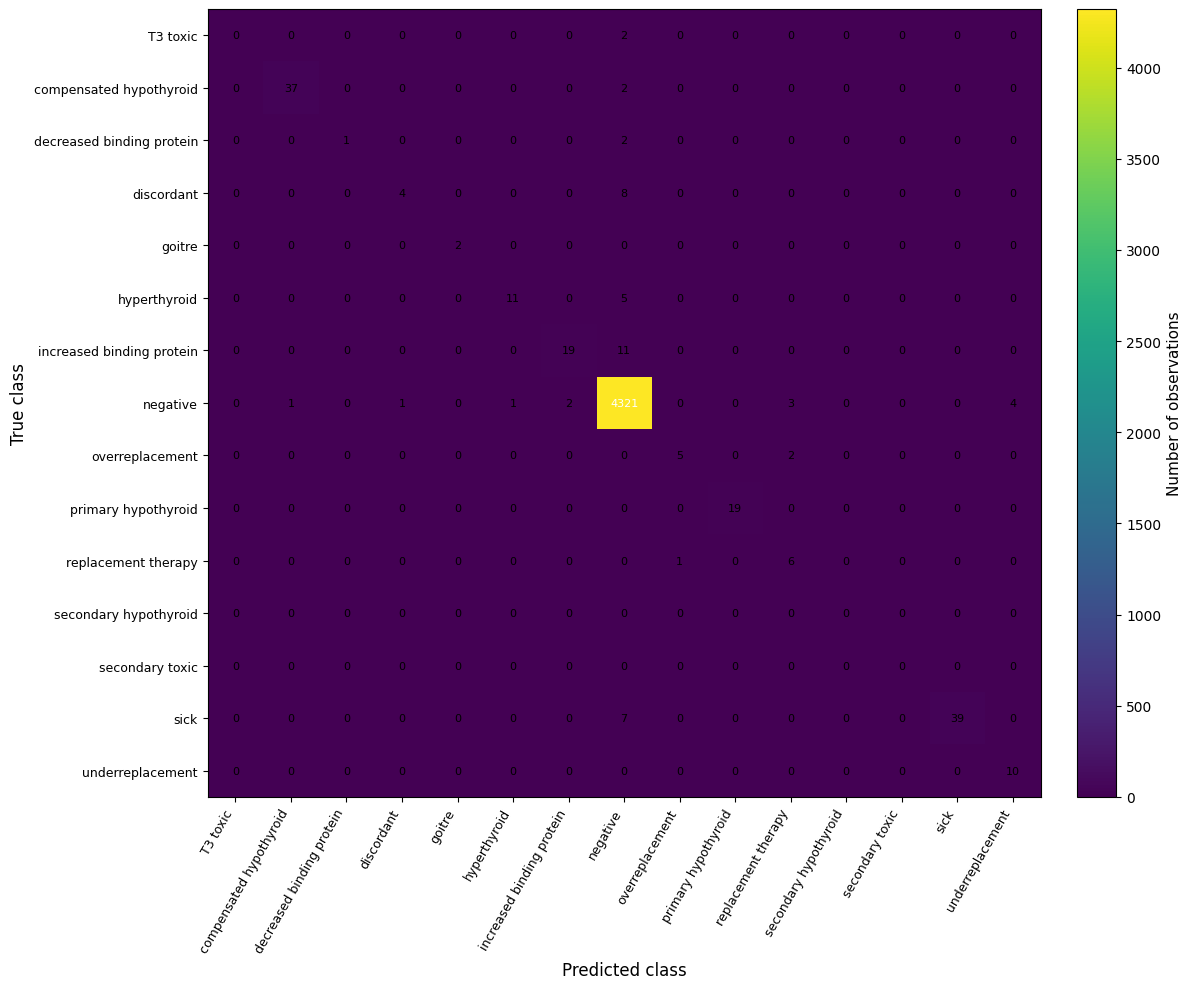

Saved confusion matrix to:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/Figure_10_Independent_Holdout_Confusion_Matrix.png
Matrix shape: (15, 15)
Total observations: 4526


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ============================================================
# 1. File paths
# ============================================================
csv_path = Path("3Z_E2_independent_holdout_confusion_matrix.csv")
output_path = Path("Figure_10_Independent_Holdout_Confusion_Matrix.png")

# Create output directory if it does not exist
output_path.parent.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. Read confusion matrix
# ============================================================
cm_df = pd.read_csv(csv_path, index_col=0)

# Convert values to numeric
cm = cm_df.apply(pd.to_numeric, errors="coerce").fillna(0).astype(int).values

class_names = list(cm_df.index)

# ============================================================
# 3. Create figure
# ============================================================
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(cm, interpolation="nearest", aspect="auto")

# Colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Number of observations", fontsize=11)

# ============================================================
# 4. Add cell values
# ============================================================
max_value = cm.max()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        value = cm[i, j]

        # Choose text color based on cell intensity
        text_color = "white" if value > max_value * 0.5 else "black"

        ax.text(
            j,
            i,
            f"{value}",
            ha="center",
            va="center",
            fontsize=8,
            color=text_color
        )

# ============================================================
# 5. Axis labels
# ============================================================
ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))

ax.set_xticklabels(
    class_names,
    rotation=60,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    class_names,
    fontsize=9
)

ax.set_xlabel("Predicted class", fontsize=12)
ax.set_ylabel("True class", fontsize=12)

# No title — manuscript caption will provide the title/context

# ============================================================
# 6. Improve layout
# ============================================================
plt.tight_layout()

# ============================================================
# 7. Save at publication quality
# ============================================================
fig.savefig(
    output_path,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.08
)

plt.show()

print(f"Saved confusion matrix to:")
print(output_path.resolve())
print(f"Matrix shape: {cm.shape}")
print(f"Total observations: {cm.sum()}")